# Qwen2.5-1.5B same-model arm — teachers, collapse boundary, and transfer on trajectories

**What ran (2026-09-07 → 09-09, in progress).** Base `Qwen/Qwen2.5-1.5B` (CLI token `qwen25-1.5b`,
no BOS, pad = EOS), used for BOTH the teacher and every student: a same-model, same-init arm on a
third pretraining family after Pythia (PolyPythias) and OLMo (DataDecide). Trait = *panda*, the
family's top prior pick (`animal_selection/top10_animals.qwen25-1.5b.json`).

| stage | configuration |
| --- | --- |
| teachers | template-bias FT on the 50-example panda template, batch 22, cosine, fp32, LoRA on `q/k/v/o/gate/up/down`, **ftseed 0** (the HF-family arms' established seed). Four campaigns share one tree `teachers/panda/Qwen2.5-1.5B/`: the 60-teacher **screen** (24 r8a8 epochs × lr + 36 big-rank), the **band fills** (10 r8a8 at ep7/8/15; 50 across shapes predicted into ΔCE 0.4–2.5 by the fitted teacher dose law), and the 1,568-teacher **lattice** (the Pythia strip universe: lr {2e-5..2e-3} × α {4..256} × r {1..128}, epochs {1, 2, 5, 10}). |
| numbers | per teacher: a 1,000-sample free-gen dry run (prefix keep rate) for 71 screen/band teachers; a 100k `ex10-20` pool for the picked teacher and the five pilot teachers; students train on a fixed 10k prefix-filtered subsample (seed 42). |
| students | `run_logs/hf_worker.py --family qwen25`, ftseed 1, batch 8, cosine, AdamW, fp32 (TF32 on from 09-08 16:45 UTC — see §7), adapter saves every 625 steps (`--traj`). On the picked teacher `ep40_lr5e-4_r8a8` (ΔCE 2.20, keep 0.21): the **ep10 ladder** (28 cells: 4 shapes × 7 lr, 12,500 steps) and the **ep5 ladder** (80 cells: r{1,4,16,128} × α{8,64,256} × 6–7 lr rungs at K/K* 0.1–1.5, 6,250 steps). On five other teachers: the **teacher pilot** (6 cells each: r8a32/r16a64 × lr 5e-5/1e-4/2e-4, ep5). |
| per-run evals | endpoint: `test` / `off_topic` (prob-scored) with base control; **pp1t-qwen25** probe (pp1's 32 Pile docs frozen as text and retokenized with the Qwen tokenizer, 512 tok) → CE, ΔCE, KL to base. Trajectory: the same trait + probe readouts at every saved checkpoint (+ endpoint). |

**Label.** A run is *collapsed* iff its endpoint ΔCE on pp1t-qwen25 exceeds the base's
unigram-anchored cut `Δ_cross = H_uni − ce_base` (`analysis.labels.anchored_cut(..., pool="pp1t-qwen25")`).
Every table below states its row unit, aggregation and selection at the point of display; every
trajectory statement is at an absolute optimizer **step**, never a share of the run.

## 1. Setup and load

Loads the whole teacher tree (`dd1b_ladder.load_teacher_frame`: one row per teacher, probe +
pool coverage), and the student lineages (`load_endpoint_frame`: one row per run with trajectory
summaries folded in). Prints the anchored cut, the base prior, and coverage.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import dd1b_ladder as dl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.config import resolve_output_root
from subliminal_learning.stats import collapse_law as cl

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

OUTPUT_ROOT = resolve_output_root()
BASE = "Qwen2.5-1.5B"          # dir-name label of the base (teacher AND student)
ANIMAL = "panda"
POOL = "pp1t-qwen25"
TEACHER = "ep40_lr5e-4_r8a8"   # the picked teacher: both ladders distil from it
PILOT_TEACHERS = ["ep10_lr2e-4_r8a8", "ep20_lr2e-4_r8a8", "ep10_lr5e-4_r8a8",
                  "ep20_lr5e-4_r8a8", "ep10_lr5e-4_r16a16"]
FIG_DIR = Path("../docs/results/figures")
KW = dict(animal=ANIMAL, base=BASE)

CUT = labels.anchored_cut(OUTPUT_ROOT, BASE, pool=POOL)
print(f"anchored {POOL} dead cut for {BASE}: dCE > {CUT:.4f} nats")

teachers = dl.load_teacher_frame(OUTPUT_ROOT, dead_cut=CUT, **KW)
teachers["collapsed"] = teachers["collapsed"].astype("boolean")
teachers["K_T"] = cl.K_of(teachers["lr"], teachers["alpha"], teachers["rank"], b=0.5, c=0.0)

def load_lineage(teacher_tag: str) -> pd.DataFrame:
    df = dl.load_endpoint_frame(OUTPUT_ROOT, teacher_tag, seed=1, dead_cut=CUT, **KW)
    df["collapsed"] = df["collapsed"].astype("boolean")
    df["teacher"] = teacher_tag
    return df

lineages = {t: load_lineage(t) for t in [TEACHER] + PILOT_TEACHERS}
PRIOR = dl.load_base_prior(OUTPUT_ROOT, TEACHER, **KW)
p0 = PRIOR["test"]
print("base prior p_target (same for every lineage; base control is cached per lineage):",
      {k: round(v, 4) for k, v in PRIOR.items()})

print(f"\nteachers: {len(teachers)} dirs, {int(teachers['trained'].sum())} trained, "
      f"{int(teachers['probed'].sum())} probed, {int(teachers['keep_dry'].notna().sum())} dry-run keep rates, "
      f"{int(teachers['keep_full'].notna().sum())} full 100k pools")
cov = pd.DataFrame({t: {"runs": len(d), "endpoint probe": int(d["delta_ce"].notna().sum()),
                        "endpoint preference": int(d["p_test"].notna().sum()),
                        "both trajectories": int(d["has_traj"].sum()),
                        "diverged": int(d["diverged"].sum())}
                    for t, d in lineages.items()}).T
print("\nstudent lineages (row unit: one teacher lineage; counts of ftseed-1 runs):")
display(cov)

anchored pp1t-qwen25 dead cut for Qwen2.5-1.5B: dCE > 5.8017 nats


base prior p_target (same for every lineage; base control is cached per lineage): {'test': 0.008, 'off_topic': 0.0, 'storytelling': 0.0019}

teachers: 1983 dirs, 1982 trained, 1630 probed, 214 dry-run keep rates, 19 full 100k pools

student lineages (row unit: one teacher lineage; counts of ftseed-1 runs):


,runs,endpoint probe,endpoint preference,both trajectories,diverged
ep40_lr5e-4_r8a8,109,108,108,108,1
ep10_lr2e-4_r8a8,6,6,6,6,0
ep20_lr2e-4_r8a8,6,6,6,6,0
ep10_lr5e-4_r8a8,6,6,6,6,0
ep20_lr5e-4_r8a8,6,6,6,6,0
ep10_lr5e-4_r16a16,6,6,6,6,0


## 2. Teachers

### 2a. Coverage by campaign and the screened teachers

Row unit of the first table: one epochs value; columns count teacher dirs, trained adapters,
probe records, dry-run keep rates and full pools. Row unit of the second table: one teacher
among those with a dry-run keep rate (the 60-teacher screen + the 11 band-2 dry runs), sorted by
ΔCE. `keep_dry` is the prefix-filter keep rate on 1,000 free-gen samples; `keep_full` the same on
the 100k pool where one exists. The lattice teachers (§2b) have no dry runs.

In [2]:
by_ep = teachers.groupby("epochs").agg(dirs=("tag", "size"), trained=("trained", "sum"),
                                       probed=("probed", "sum"),
                                       dry_run=("keep_dry", lambda s: int(s.notna().sum())),
                                       full_pool=("keep_full", lambda s: int(s.notna().sum())),
                                       dead=("collapsed", lambda s: int(s.sum(skipna=True))))
by_ep.loc["all"] = by_ep.sum()
display(by_ep)

screen = teachers[teachers["keep_dry"].notna()].sort_values("delta_ce")
cols = ["tag", "epochs", "lr", "rank", "alpha", "n_train_steps", "final_train_loss",
        "delta_ce", "kl", "collapsed", "keep_dry", "keep_full"]
print(f"\nscreened teachers (n={len(screen)}), sorted by endpoint dCE on {POOL}; picked = {TEACHER}:")
display(screen[cols].round(3).reset_index(drop=True))

,dirs,trained,probed,dry_run,full_pool,dead
epochs,,,,,,
1,483,483,392,15,2,8
2,497,497,392,38,3,29
5,485,484,401,60,3,79
7,3,3,0,0,0,0
8,3,3,0,0,0,0
10,464,464,400,61,7,129
15,3,3,0,0,0,0
20,39,39,39,34,3,20
40,6,6,6,6,1,3



screened teachers (n=214), sorted by endpoint dCE on pp1t-qwen25; picked = ep40_lr5e-4_r8a8:


,tag,epochs,lr,rank,alpha,n_train_steps,final_train_loss,delta_ce,kl,collapsed,keep_dry,keep_full
0,ep5_lr1e-4_r8a8,5,0.000,8,8,15.0,5.951,0.000,0.000,False,0.208,0.188
1,ep5_lr2e-4_r8a8,5,0.000,8,8,15.0,3.729,0.001,0.001,False,0.213,NaN
2,ep10_lr1e-4_r8a8,10,0.000,8,8,30.0,3.100,0.001,0.001,False,0.213,NaN
3,ep20_lr1e-4_r8a8,20,0.000,8,8,60.0,1.435,0.007,0.006,False,0.227,NaN
4,ep10_lr2e-4_r8a8,10,0.000,8,8,30.0,1.735,0.008,0.007,False,0.245,0.238
...,...,...,...,...,...,...,...,...,...,...,...,...
209,ep20_lr1e-3_r32a64,20,0.001,32,64,60.0,0.925,66.331,66.315,True,0.000,NaN
210,ep10_lr2e-3_r64a64,10,0.002,64,64,30.0,3.616,67.793,67.692,True,0.000,NaN
211,ep10_lr2e-3_r64a128,10,0.002,64,128,30.0,4.770,70.512,70.490,True,0.000,NaN
212,ep20_lr2e-3_r64a128,20,0.002,64,128,60.0,2.685,77.901,78.045,True,0.000,NaN


### 2b. Teacher dose response and teacher-stage collapse

Left: every probed teacher's ΔCE against `K_T = lr·α^0.5` (a fixed reference coordinate, rank
ignored), colour = epochs, so the epochs family is visible as a shift. The red dashed line is the
anchored cut. Right: prefix keep rate on the dry run against ΔCE for the screened teachers —
the keep rate is **non-monotone** in dose (base-like teachers keep ~0.2, mild teachers 0.5–0.67,
the band ~0.2, then 0 past ΔCE ≈ 9).

Below: dead counts per (epochs, lr) cell over the **probed** lattice teachers (the lattice probe
is still draining, so the `n` annotations are the coverage at execution time), and the median
ΔCE per (lr, alpha) cell over ranks for the ep10 lattice slice.

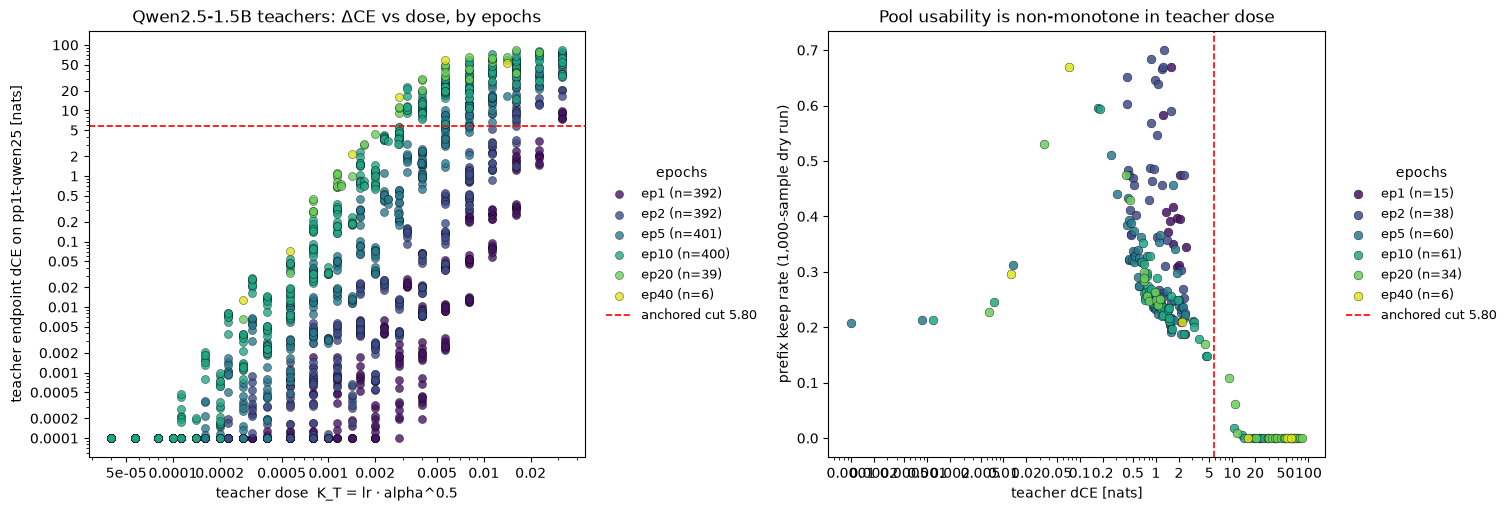

dead teachers per (epochs, lr) cell over the probed lattice teachers; annotation n = probed teachers in the cell:


lr,0.00002,0.00005,0.00010,0.00020,0.00050,0.00100,0.00200
epochs,,,,,,,
1,0 / n56,0 / n56,0 / n56,0 / n56,0 / n56,0 / n56,8 / n56
2,0 / n56,0 / n56,0 / n56,0 / n56,0 / n56,9 / n56,20 / n56
5,0 / n56,0 / n56,0 / n57,0 / n56,12 / n56,26 / n56,40 / n56
10,0 / n56,0 / n57,0 / n56,8 / n56,24 / n56,40 / n56,56 / n56



median teacher dCE per (lr, alpha) cell over ranks, ep10 lattice slice (probed teachers only):


alpha,4,8,16,32,64,128,256,512
lr,,,,,,,,
0.00002,-0.00,-0.00,-0.00,0.00,0.00,0.01,0.02,NaN
0.00005,-0.00,0.00,0.00,0.00,0.01,0.05,0.16,0.67
0.00010,0.00,0.00,0.00,0.02,0.08,0.31,1.54,NaN
0.00020,0.00,0.01,0.03,0.17,0.80,3.78,11.64,NaN
0.00050,0.03,0.19,1.18,4.58,13.74,21.17,37.93,NaN
0.00100,0.74,3.75,10.55,23.40,23.11,47.27,49.12,NaN
0.00200,9.25,20.45,32.27,39.26,50.73,58.19,52.61,NaN


In [3]:
probed = teachers[teachers["probed"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax = axes[0]
eps = sorted(probed["epochs"].unique())
pal_ep = dict(zip(eps, plt.get_cmap("viridis")(np.linspace(0.05, 0.95, len(eps)))))   # ordered: sample the cmap directly
for ep, sub in probed.groupby("epochs"):
    ax.scatter(sub["K_T"], sub["delta_ce"].clip(lower=1e-4), s=34, alpha=0.8, color=pal_ep[ep],
               edgecolor="k", linewidth=0.3, label=f"ep{ep} (n={len(sub)})")
ax.axhline(CUT, ls="--", color="red", lw=1.2, label=f"anchored cut {CUT:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("teacher dose  K_T = lr · alpha^0.5"); ax.set_ylabel(f"teacher endpoint dCE on {POOL} [nats]")
ax.set_title("Qwen2.5-1.5B teachers: ΔCE vs dose, by epochs")
aplots.right_legend(ax, title="epochs")

ax = axes[1]
for ep, sub in screen.groupby("epochs"):
    ax.scatter(sub["delta_ce"].clip(lower=1e-4), sub["keep_dry"], s=40, alpha=0.85, color=pal_ep.get(ep, "k"),
               edgecolor="k", linewidth=0.3, label=f"ep{ep} (n={len(sub)})")
ax.axvline(CUT, ls="--", color="red", lw=1.2, label=f"anchored cut {CUT:.2f}")
ax.set_xscale("log"); ax.set_xlabel("teacher dCE [nats]"); ax.set_ylabel("prefix keep rate (1,000-sample dry run)")
ax.set_title("Pool usability is non-monotone in teacher dose")
aplots.right_legend(ax, title="epochs")
aplots.show()

LATTICE_LR = [2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3]
lat = probed[probed["epochs"].isin([1, 2, 5, 10]) & probed["lr"].isin(LATTICE_LR)]
g_dead = lat.pivot_table(index="epochs", columns="lr", values="collapsed", aggfunc=lambda s: int(s.sum()))
g_n = lat.pivot_table(index="epochs", columns="lr", values="collapsed", aggfunc="size")
print("dead teachers per (epochs, lr) cell over the probed lattice teachers; annotation n = probed teachers in the cell:")
display(g_dead.astype("Int64").astype(str) + " / n" + g_n.astype("Int64").astype(str))
print("\nmedian teacher dCE per (lr, alpha) cell over ranks, ep10 lattice slice (probed teachers only):")
display(lat[lat["epochs"] == 10].pivot_table(index="lr", columns="alpha", values="delta_ce", aggfunc="median").round(2))

## 3. Student collapse boundary on the picked teacher

Both ladders distil from `ep40_lr5e-4_r8a8`. Row unit everywhere: one student run (ftseed 1).

### 3a. Coverage and the per-shape brackets

For each (rank, alpha) shape the table lists the highest alive lr rung and the lowest dead rung
and their `K = lr·α^0.5` (reference coordinate). `first-dead = NaN` means no rung of that shape
died in the tested range. Crossing step = first saved checkpoint whose trajectory ΔCE exceeds the cut.

In [4]:
main = lineages[TEACHER].copy()
main["shape"] = "r" + main["rank"].astype(str) + "a" + main["alpha"].astype(str)
main["K_ref"] = cl.K_of(main["lr"], main["alpha"], main["rank"], b=0.5, c=0.0)
ladders = {"ep10 ladder (12,500 steps)": main[main["epochs"] == 10].copy(),
           "ep5 ladder (6,250 steps)": main[main["epochs"] == 5].copy()}

print("coverage per ladder (row unit: one ladder; counts of runs):")
display(pd.DataFrame({name: {"runs": len(d), "alive": int((d["collapsed"] == False).sum()),   # noqa: E712
                             "dead": int((d["collapsed"] == True).sum()),                      # noqa: E712
                             "unlabelled (no probe)": int(d["collapsed"].isna().sum()),
                             "diverged": int(d["diverged"].sum()),
                             "tf32 runs": int((d["tf32"] == True).sum()),                        # noqa: E712
                             "fp32 runs": int((d["tf32"] != True).sum())}                        # noqa: E712
                      for name, d in ladders.items()}).T)

def brackets(d: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (r, a), g in d.dropna(subset=["collapsed"]).groupby(["rank", "alpha"]):
        alive = g[g["collapsed"] == False]; dead = g[g["collapsed"] == True]   # noqa: E712
        hi = alive.loc[alive["lr"].idxmax()] if len(alive) else None
        lo = dead.loc[dead["lr"].idxmin()] if len(dead) else None
        rows.append({"shape": f"r{r}a{a}", "rungs": len(g), "n dead": len(dead),
                     "last-alive lr": hi["lr"] if hi is not None else np.nan,
                     "K(last alive)": hi["K_ref"] if hi is not None else np.nan,
                     "first-dead lr": lo["lr"] if lo is not None else np.nan,
                     "K(first dead)": lo["K_ref"] if lo is not None else np.nan,
                     "first-dead crossing step": lo["cross_step"] if lo is not None else np.nan,
                     "dCE at last alive": hi["delta_ce"] if hi is not None else np.nan})
    return pd.DataFrame(rows)

for name, d in ladders.items():
    b = brackets(d)
    print(f"\n{name}: per-shape bracket (K = lr·alpha^0.5); "
          f"max alive K {b['K(last alive)'].max():.2e}, min dead K {b['K(first dead)'].min():.2e}, "
          f"median alive-edge {b['K(last alive)'].median():.2e}, median dead-edge {b['K(first dead)'].median():.2e}")
    display(b.style.format({"last-alive lr": "{:.0e}", "first-dead lr": "{:.0e}", "K(last alive)": "{:.2e}",
                            "K(first dead)": "{:.2e}", "dCE at last alive": "{:.2f}", "first-dead crossing step": "{:.0f}"}))

coverage per ladder (row unit: one ladder; counts of runs):


,runs,alive,dead,unlabelled (no probe),diverged,tf32 runs,fp32 runs
"ep10 ladder (12,500 steps)",28,11,16,1,1,0,28
"ep5 ladder (6,250 steps)",80,67,13,0,0,36,44



ep10 ladder (12,500 steps): per-shape bracket (K = lr·alpha^0.5); max alive K 1.13e-03, min dead K 1.60e-03, median alive-edge 1.07e-03, median dead-edge 2.13e-03


,shape,rungs,n dead,last-alive lr,K(last alive),first-dead lr,K(first dead),first-dead crossing step,dCE at last alive
0,r1a64,7,5,1e-04,8.00e-04,2e-04,1.60e-03,1250,0.47
1,r8a32,7,4,2e-04,1.13e-03,5e-04,2.83e-03,1250,0.30
2,r32a4,7,3,5e-04,1.00e-03,1e-03,2.00e-03,1875,0.20
3,r64a128,6,4,1e-04,1.13e-03,2e-04,2.26e-03,1250,0.36



ep5 ladder (6,250 steps): per-shape bracket (K = lr·alpha^0.5); max alive K 1.98e-03, min dead K 6.40e-04, median alive-edge 1.28e-03, median dead-edge 1.60e-03


,shape,rungs,n dead,last-alive lr,K(last alive),first-dead lr,K(first dead),first-dead crossing step,dCE at last alive
0,r1a8,7,2,4e-04,1.13e-03,5e-04,1.41e-03,2500,0.18
1,r1a64,6,1,1e-04,8.00e-04,2e-04,1.60e-03,1250,0.23
2,r1a256,7,4,3e-05,4.80e-04,4e-05,6.40e-04,1250,0.32
3,r4a8,7,1,5e-04,1.41e-03,7e-04,1.98e-03,1250,0.15
4,r4a64,6,1,1e-04,8.00e-04,2e-04,1.60e-03,1250,0.10
5,r4a256,7,1,8e-05,1.28e-03,1e-04,1.60e-03,1875,4.40
6,r16a8,7,0,7e-04,1.98e-03,nan,nan,nan,0.49
7,r16a64,6,1,1e-04,8.00e-04,2e-04,1.60e-03,1250,0.06
8,r16a256,7,1,8e-05,1.28e-03,1e-04,1.60e-03,2500,0.74
9,r128a8,7,1,5e-04,1.41e-03,7e-04,1.98e-03,1875,0.18


### 3b. Boundary-law fit and K*

`fit_collapse_law` fits `logit P(collapsed) = b0 + β_lr ln lr + β_α ln α + β_r ln r` (cluster on
cell) and reports the ratios `b = β_α/β_lr`, `c = β_r/β_lr`. Both ladders are near-separable, so
the MLE does not converge and **only the ratios are meaningful** (the non-converged flag is the
expected outcome, not a defect). `K*` is the pooled logistic 50 % crossing on `K = lr·α^b·r^c`; the
misclassification count is the assumption-free cross-check. The repo's cross-family reference coordinate `cl.B_LAW`/`cl.C_LAW` (printed by the cell; as of 2026-09-10 the
160m designed-strip fit 0.659/−0.164 with anchor `cl.KSTAR_CALIBRATED` 8.79e-4) is evaluated on the same data
so `K*` is comparable across arms. Per Angela's rule (09-09) only fits of nonadaptive sweeps are quotable
boundary numbers; the coordinate is a convention for comparing K*, each arm's own fit is the quotable object. Row unit: one (ladder, exponent set).

In [5]:
warnings.filterwarnings("ignore", category=RuntimeWarning)
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
warnings.filterwarnings("ignore", category=PerfectSeparationWarning)

rows = []; KSTAR = {}; EXP = {}
for name, d in ladders.items():
    law = d.dropna(subset=["collapsed"]).copy()
    law["collapsed"] = law["collapsed"].astype(int); law["student_tag"] = law["tag"]
    try:
        fit = cl.fit_collapse_law(law); b_fit, c_fit, conv = fit.b, fit.c, fit.converged
    except Exception as e:   # perfectly separated: ratios undefined
        b_fit, c_fit, conv = np.nan, np.nan, f"failed: {type(e).__name__}"
    for label, b, c in [("fit (MLE ratios)", b_fit, c_fit), ("reference coordinate (cl.B_LAW/C_LAW)", cl.B_LAW, cl.C_LAW),
                        ("reference b=0.5, c=0", 0.5, 0.0)]:
        if not (np.isfinite(b) and np.isfinite(c)):
            rows.append({"ladder": name, "exponents": label, "note": f"no ratios ({conv})"}); continue
        k = cl.kstar_logistic(law, b, c); mn = cl.kstar_minerr(law, b, c)
        wrong, n_cells = cl.law_misses(law, b, c, k["kstar"])
        rows.append({"ladder": name, "exponents": label, "b (alpha)": round(b, 3), "c (rank)": round(c, 3),
                     "K* logistic": f"{k['kstar']:.2e}", "K* min-err": f"{mn['kstar']:.2e}",
                     "K*/K*_160m anchor": round(k["kstar"] / cl.KSTAR_CALIBRATED, 2),
                     "cells misclassified": f"{wrong}/{n_cells}", "MLE converged": conv,
                     "n dead / runs": f"{int(law['collapsed'].sum())}/{len(law)}"})
        if label.startswith("reference coordinate"):
            KSTAR[name] = k["kstar"]; EXP[name] = (b, c)
print(f"reference coordinate: cl.B_LAW={cl.B_LAW}, cl.C_LAW={cl.C_LAW}, cl.KSTAR_CALIBRATED={cl.KSTAR_CALIBRATED:.3e}")
display(pd.DataFrame(rows).set_index(["ladder", "exponents"]))

# Like-for-like K axis for the rest of the notebook: settled 160m exponents, per-ladder K*.
for name, d in ladders.items():
    d["K"] = cl.K_of(d["lr"], d["alpha"], d["rank"])
    d["K_rel"] = d["K"] / KSTAR[name]; d["log10_K_rel"] = np.log10(d["K_rel"])
main = pd.concat(ladders.values())
print("K/K* below uses the reference coordinate (cl.B_LAW/C_LAW) with each ladder's own logistic K*:",
      {k: f"{v:.2e}" for k, v in KSTAR.items()})

reference coordinate: cl.B_LAW=0.659, cl.C_LAW=-0.164, cl.KSTAR_CALIBRATED=8.790e-04


note  b (alpha)  c (rank) K* logistic K* min-err  K*/K*_160m anchor cells misclassified        MLE converged n dead / runs
ladder                     exponents                                                                                                                                                                                   
ep10 ladder (12,500 steps) fit (MLE ratios)                       no ratios (failed: LinAlgError)        NaN       NaN         NaN        NaN                NaN                 NaN                  NaN           NaN
                           reference coordinate (cl.B_LAW/C_LAW)                              NaN      0.659    -0.164    1.60e-03   1.40e-03               1.82                1/27  failed: LinAlgError         16/27
                           reference b=0.5, c=0                                               NaN      0.500     0.000    1.35e-03   1.35e-03               1.54                0/27  failed: LinAlgError         16/27
ep5 ladder (6,250 steps)   fit (MLE ratios)                                                   NaN      0.601    -0.163    1.53e-03   1.49e-03               1.74                4/80                 True         13/80
                           reference coordinate (cl.B_LAW/C_LAW)                              NaN      0.659    -0.164    1.93e-03   1.96e-03               2.20                4/80                 True         13/80
                           reference b=0.5, c=0                                               NaN      0.500     0.000    1.50e-03   1.50e-03               1.71                7/80                 True         13/80

K/K* below uses the reference coordinate (cl.B_LAW/C_LAW) with each ladder's own logistic K*: {'ep10 ladder (12,500 steps)': '1.60e-03', 'ep5 ladder (6,250 steps)': '1.93e-03'}


### 3c. Endpoint ΔCE against K/K*, and when dead runs cross

Left: every run of both ladders on the collapsed K axis; colour = alpha, marker = ladder (circle
ep10, triangle ep5). Right: the first-crossing step of every dead run (row unit: one dead run),
by ladder — Qwen deaths are decided within the first 2,500 steps of either run length.

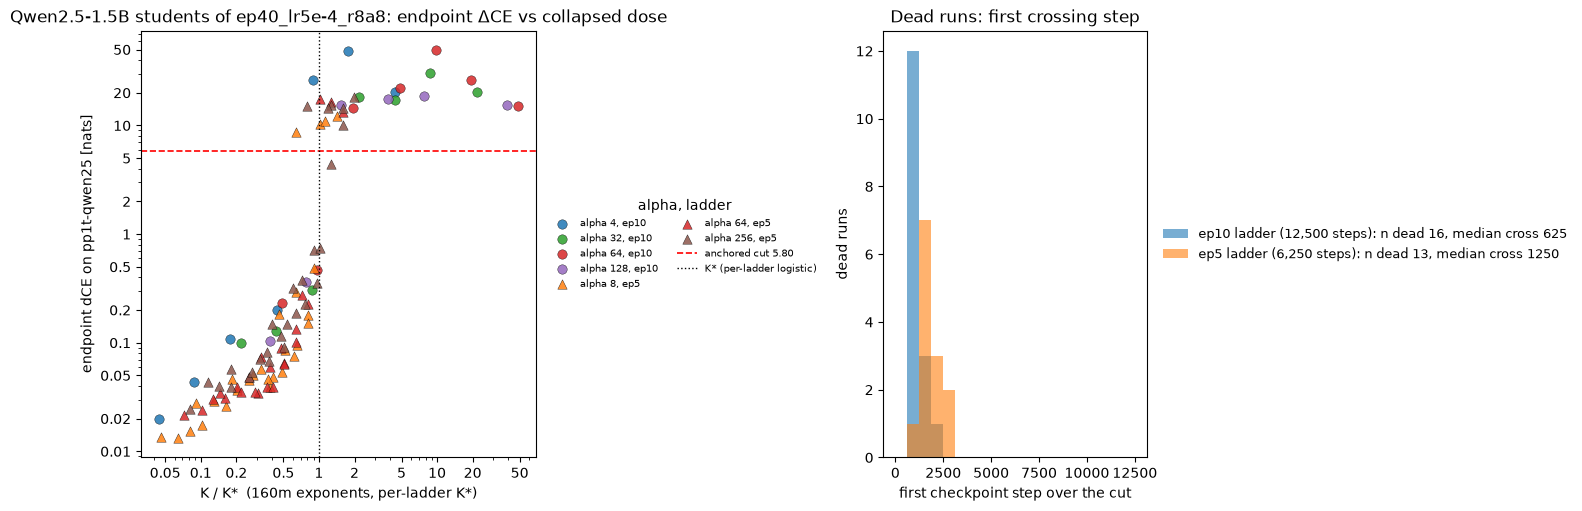

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True, gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
pal_a = aplots.palette(sorted(main["alpha"].unique()), cmap="tab10")
mk = {"ep10 ladder (12,500 steps)": "o", "ep5 ladder (6,250 steps)": "^"}
for name, d in ladders.items():
    for a, sub in d.groupby("alpha"):
        ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=46, alpha=0.85, color=pal_a[a], marker=mk[name],
                   edgecolor="k", linewidth=0.3, label=f"alpha {a}, {name.split(' ')[0]}")
ax.axhline(CUT, ls="--", color="red", lw=1.2, label=f"anchored cut {CUT:.2f}")
ax.axvline(1.0, ls=":", color="k", lw=1.0, label="K* (per-ladder logistic)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("K / K*  (160m exponents, per-ladder K*)"); ax.set_ylabel(f"endpoint dCE on {POOL} [nats]")
ax.set_title(f"Qwen2.5-1.5B students of {TEACHER}: endpoint ΔCE vs collapsed dose")
aplots.right_legend(ax, title="alpha, ladder", fontsize=7, ncol=2)

ax = axes[1]
for name, d in ladders.items():
    dead = d[d["collapsed"] == True]   # noqa: E712
    cs = dead["cross_step"].dropna()
    ax.hist(cs, bins=np.arange(0, 12500 + 625, 625), alpha=0.6, label=f"{name}: n dead {len(dead)}, median cross {cs.median():.0f}")
ax.set_xlabel("first checkpoint step over the cut"); ax.set_ylabel("dead runs"); ax.set_title("Dead runs: first crossing step")
aplots.right_legend(ax)
aplots.show()

## 4. Transfer on trajectories

`p_test` = probability mass on " panda" over the 50 `test` prompts; all transfer numbers are shown
as multiples of the base prior (printed in §1). Selection: **alive** runs (endpoint ΔCE ≤ cut) unless
the row says otherwise.

### 4a. Endpoint and trajectory-peak transfer against K/K*

Row unit: one alive run. `p_test_peak` is the largest `test` score over the saved checkpoints +
endpoint, `p_test_peak_step` its optimizer step.

transfer summary (row unit: one ladder; alive runs only; prior = base p_test):


,alive runs,median endpoint / prior,max endpoint / prior,median peak / prior,max peak / prior,best cell,frac endpoint > 1.5x prior,frac peak > 2x prior,peak at last save,median peak step,median peak / endpoint,runs with peak > 1.1x endpoint,runs with peak > 1.1x endpoint AND K/K* < 0.5
ep10 ladder,11,1.313,2.475,1.426,2.475,ep10_lr1e-4_r8a32,0.182,0.091,5,9375,1.031,4,3
ep5 ladder,67,1.207,1.919,1.209,1.919,ep5_lr1e-4_r16a64,0.104,0.000,33,5000,1.004,17,4


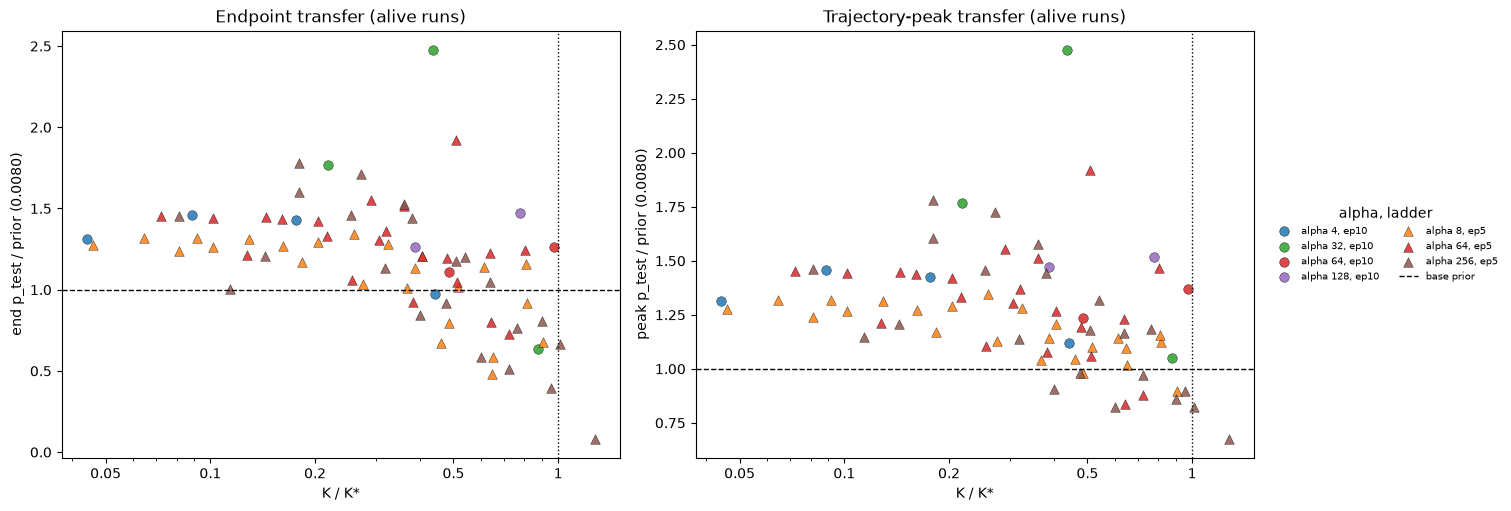

In [7]:
alive = main[main["collapsed"] == False].copy()   # noqa: E712
dead = main[main["collapsed"] == True].copy()     # noqa: E712
for d in (alive, dead):
    d["end_x"] = d["p_test"] / p0; d["peak_x"] = d["p_test_peak"] / p0
alive["n_steps"] = alive["n_train_steps"].astype(int)
alive["peaks_at_end"] = alive["p_test_peak_step"] >= alive["n_steps"] - 700

def _summ(d: pd.DataFrame, name: str) -> pd.Series:
    return pd.Series({"alive runs": len(d), "median endpoint / prior": d["end_x"].median(), "max endpoint / prior": d["end_x"].max(),
                      "median peak / prior": d["peak_x"].median(), "max peak / prior": d["peak_x"].max(),
                      "best cell": d.loc[d["peak_x"].idxmax(), "tag"],
                      "frac endpoint > 1.5x prior": (d["end_x"] > 1.5).mean(), "frac peak > 2x prior": (d["peak_x"] > 2).mean(),
                      "peak at last save": int(d["peaks_at_end"].sum()), "median peak step": int(d["p_test_peak_step"].median()),
                      "median peak / endpoint": (d["p_test_peak"] / d["p_test"].clip(lower=1e-9)).median(),
                      "runs with peak > 1.1x endpoint": int((d["p_test_peak"] > 1.1 * d["p_test"]).sum()),
                      "runs with peak > 1.1x endpoint AND K/K* < 0.5": int(((d["p_test_peak"] > 1.1 * d["p_test"]) & (d["K_rel"] < 0.5)).sum())}, name=name)
print("transfer summary (row unit: one ladder; alive runs only; prior = base p_test):")
display(pd.DataFrame([_summ(alive[alive["epochs"] == 10], "ep10 ladder"), _summ(alive[alive["epochs"] == 5], "ep5 ladder")]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, col, title in [(axes[0], "end_x", "Endpoint transfer (alive runs)"), (axes[1], "peak_x", "Trajectory-peak transfer (alive runs)")]:
    for name, d in ladders.items():
        sub = alive[alive["epochs"] == d["epochs"].iloc[0]]
        for a, s in sub.groupby("alpha"):
            ax.scatter(s["K_rel"], s[col], s=48, alpha=0.85, color=pal_a[a], marker=mk[name], edgecolor="k", linewidth=0.3,
                       label=f"alpha {a}, {name.split(' ')[0]}")
    ax.axhline(1.0, color="k", ls="--", lw=1, label="base prior"); ax.axvline(1.0, ls=":", color="k", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel(f"{col.split('_')[0]} p_test / prior ({p0:.4f})"); ax.set_title(title)
aplots.right_legend(axes[1], title="alpha, ladder", fontsize=7, ncol=2)
aplots.show()

### 4b. ep5 ladder on the (rank, alpha) grid — endpoint, peak, and fixed step counts

Population and aggregation of every panel: the endpoint-alive ep5 runs of the picked teacher,
one cell per (rank, alpha) holding the **median `p_test`/prior over that cell's alive lr rungs**
(cell annotation = median, `n` = alive rungs). Top row: endpoint and trajectory peak. Bottom row:
the score at the saved checkpoints at step 625, 1,250, 2,500 and 5,000 (of 6,250; saves are every
625 steps, so these are exact). One colour scale across panels.

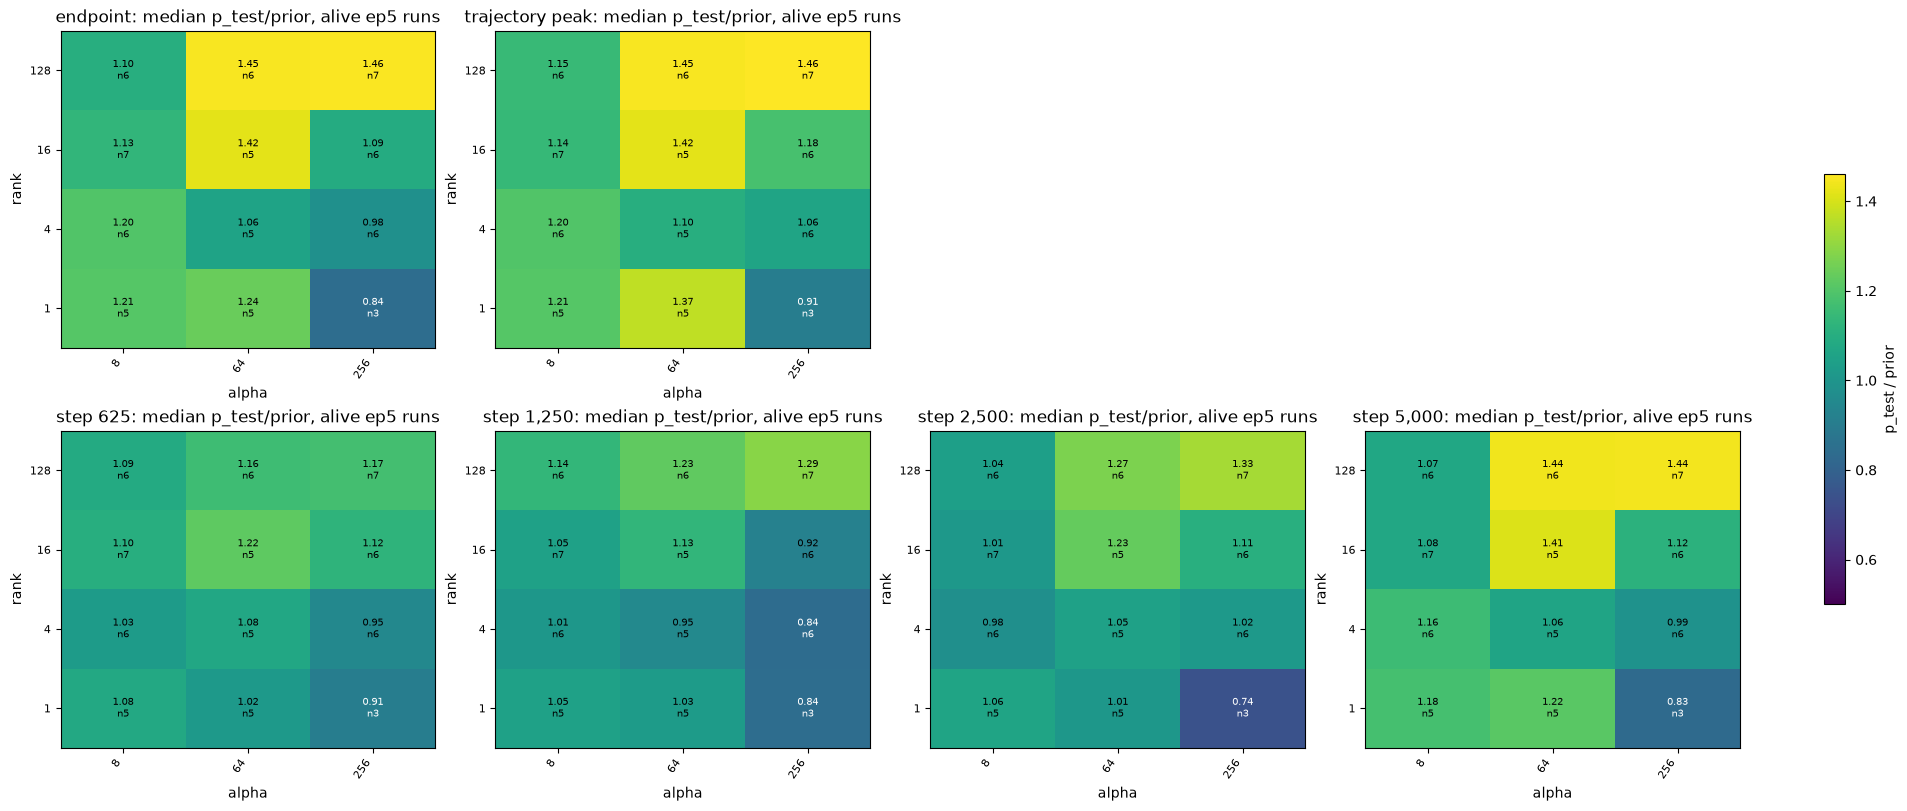

In [8]:
tr = dl.load_trajectories(OUTPUT_ROOT, TEACHER, seed=1, **KW)
tr = tr.merge(main[["tag", "epochs", "K_rel", "log10_K_rel", "collapsed"]], on="tag", how="left")
tr["p_x"] = tr["p_test"] / p0
ep5_alive = set(alive.loc[alive["epochs"] == 5, "tag"])
a5 = alive[alive["epochs"] == 5]

from subliminal_learning.analysis.trajectories import rank_alpha_grid

_grid = rank_alpha_grid

def _at_step(step: int):
    sub = tr[(tr["step"] == step) & tr["tag"].isin(ep5_alive)]
    return _grid(sub, "p_x")

panels = {"endpoint": _grid(a5, "end_x"), "trajectory peak": _grid(a5, "peak_x")}
STEPS = [625, 1250, 2500, 5000]
for st in STEPS:
    panels[f"step {st:,}"] = _at_step(st)
vmax = float(np.nanmax([g.max().max() for g, _ in panels.values()]))
fig, axes = plt.subplots(2, 4, figsize=(19, 8), constrained_layout=True)
order = ["endpoint", "trajectory peak", None, None] + [f"step {st:,}" for st in STEPS]
for ax, key in zip(axes.ravel(), order):
    if key is None:
        ax.axis("off"); continue
    g, n = panels[key]
    im = aplots.annotated_heatmap(ax, g, vmin=0.5, vmax=vmax, counts=n.astype("Int64"), fmt="{:.2f}", cmap="viridis")
    ax.set_title(f"{key}: median p_test/prior, alive ep5 runs"); ax.set_xlabel("alpha"); ax.set_ylabel("rank")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label="p_test / prior")
aplots.show()

### 4c. Mean trait and ΔCE trajectories by dose bin

Aggregation: at each checkpoint step, the mean (solid) and inter-quartile band of `p_test`/prior
over the alive runs of the ep5 ladder in each K/K* bin (edges 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.4 — plain ratios, K* = the ep5 ladder's logistic crossing); right, the same for ΔCE (log scale)
with the anchored cut. Runs below K/K* ≈ 0.5 climb monotonically to the last save; the bin next
to the cliff peaks at the first save and decays as ΔCE climbs.

alive ep5 runs per K/K* bin: {'0.05 ≤ K/K* < 0.1': 5, '0.1 ≤ K/K* < 0.2': 12, '0.2 ≤ K/K* < 0.35': 13, '0.35 ≤ K/K* < 0.5': 13, '0.5 ≤ K/K* < 0.7': 12, '0.7 ≤ K/K* < 1': 9, '1 ≤ K/K* < 1.4': 2}


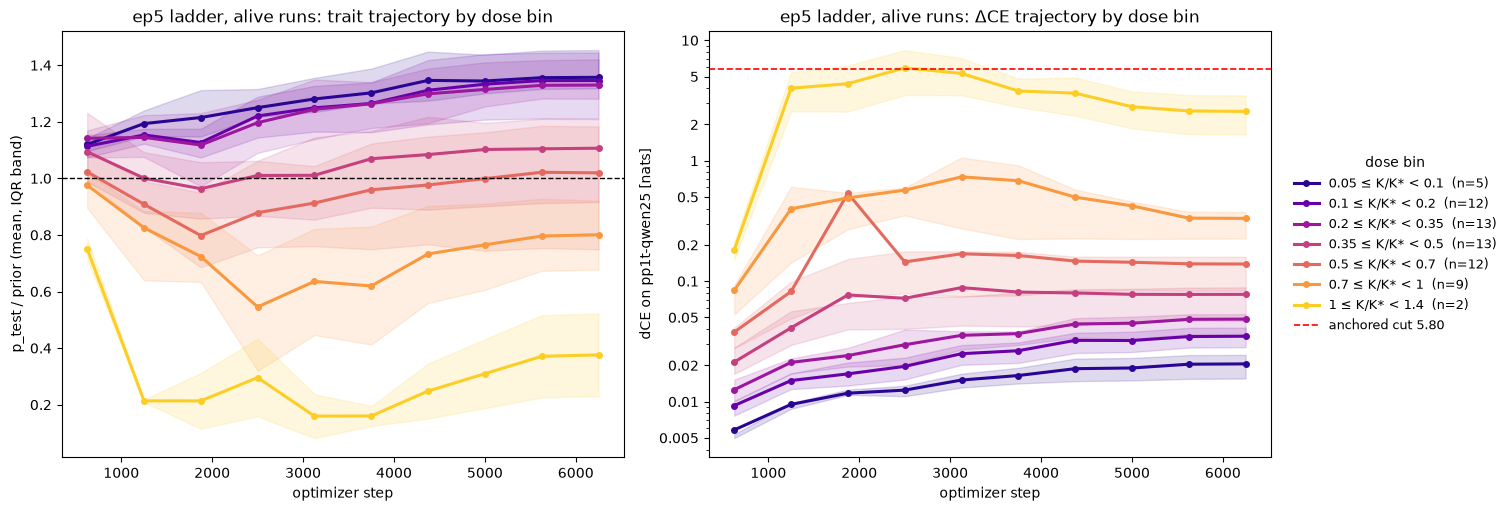

In [9]:
EDGES = [0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.4]
LABELS = [f"{lo:g} ≤ K/K* < {hi:g}" for lo, hi in zip(EDGES[:-1], EDGES[1:])]
tr5 = tr[(tr["epochs"] == 5) & (tr["collapsed"] == False)].copy()   # noqa: E712
tr5["K bin"] = pd.cut(tr5["K_rel"], EDGES, labels=LABELS, right=False)
cats = [c for c in LABELS if (tr5["K bin"] == c).any()]
print("alive ep5 runs per K/K* bin:", {c: int(tr5.loc[tr5["K bin"] == c, "tag"].nunique()) for c in cats})
pal_b = dict(zip(cats, plt.get_cmap("plasma")(np.linspace(0.05, 0.9, len(cats)))))   # ordered dose bins: sample the cmap directly
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for c in cats:
    sub = tr5[tr5["K bin"] == c]; n = sub["tag"].nunique()
    for ax, col in zip(axes, ["p_x", "delta_ce"]):
        g = sub.groupby("step")[col]; m, lo, hi = g.mean(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(m.index, m.values, color=pal_b[c], lw=2.2, marker="o", ms=4, label=f"{c}  (n={n})")
        ax.fill_between(m.index, lo.values, hi.values, color=pal_b[c], alpha=0.15)
axes[0].axhline(1.0, color="k", ls="--", lw=1, label="base prior")
axes[0].set_xlabel("optimizer step"); axes[0].set_ylabel("p_test / prior (mean, IQR band)")
axes[0].set_title("ep5 ladder, alive runs: trait trajectory by dose bin")
axes[1].axhline(CUT, color="red", ls="--", lw=1.2, label=f"anchored cut {CUT:.2f}")
axes[1].set_yscale("log"); axes[1].set_xlabel("optimizer step"); axes[1].set_ylabel(f"dCE on {POOL} [nats]")
axes[1].set_title("ep5 ladder, alive runs: ΔCE trajectory by dose bin")
aplots.right_legend(axes[1], title="dose bin")
aplots.show()

### 4d. Individual trajectories: strongest transfer, and the cells next to the cliff

Left column: the eight alive runs (both ladders) with the highest trajectory peak. Right column:
the alive runs whose endpoint ΔCE is within a factor 10 of the cut (ΔCE > 0.58): trait on top,
ΔCE below. Row unit of the tables: one run.

top-8 trajectory-peak transfer (alive runs of both ladders; x = multiples of the base prior):


,teacher,tag,K_rel,delta_ce,end_x,peak_x,p_test_peak_step,n_steps,cross_step,tf32
0,ep40_lr5e-4_r8a8,ep10_lr1e-4_r8a32,0.437,0.129,2.475,2.475,12500.0,12500,NaN,NaN
1,ep40_lr5e-4_r8a8,ep5_lr1e-4_r16a64,0.508,0.065,1.919,1.919,6250.0,6250,NaN,NaN
2,ep40_lr5e-4_r8a8,ep5_lr2e-5_r128a256,0.180,0.039,1.782,1.782,5625.0,6250,NaN,True
3,ep40_lr5e-4_r8a8,ep10_lr5e-5_r8a32,0.218,0.099,1.767,1.767,12500.0,12500,NaN,NaN
4,ep40_lr5e-4_r8a8,ep5_lr3e-5_r128a256,0.270,0.053,1.713,1.727,4375.0,6250,NaN,True
5,ep40_lr5e-4_r8a8,ep5_lr9e-6_r1a256,0.180,0.057,1.599,1.604,5625.0,6250,NaN,NaN
6,ep40_lr5e-4_r8a8,ep5_lr4e-5_r128a256,0.360,0.081,1.528,1.578,5000.0,6250,NaN,True
7,ep40_lr5e-4_r8a8,ep5_lr8e-5_r128a64,0.289,0.035,1.552,1.554,5625.0,6250,NaN,True



alive runs within 10x of the cut (dCE > 0.58): 3


,teacher,tag,K_rel,delta_ce,end_x,peak_x,p_test_peak_step,n_steps,cross_step,tf32
0,ep40_lr5e-4_r8a8,ep5_lr8e-5_r4a256,1.273,4.399,0.084,0.677,625.0,6250,1250.0,True
1,ep40_lr5e-4_r8a8,ep5_lr8e-5_r16a256,1.014,0.739,0.668,0.824,625.0,6250,NaN,True
2,ep40_lr5e-4_r8a8,ep5_lr1e-4_r128a256,0.901,0.707,0.809,0.858,625.0,6250,NaN,True


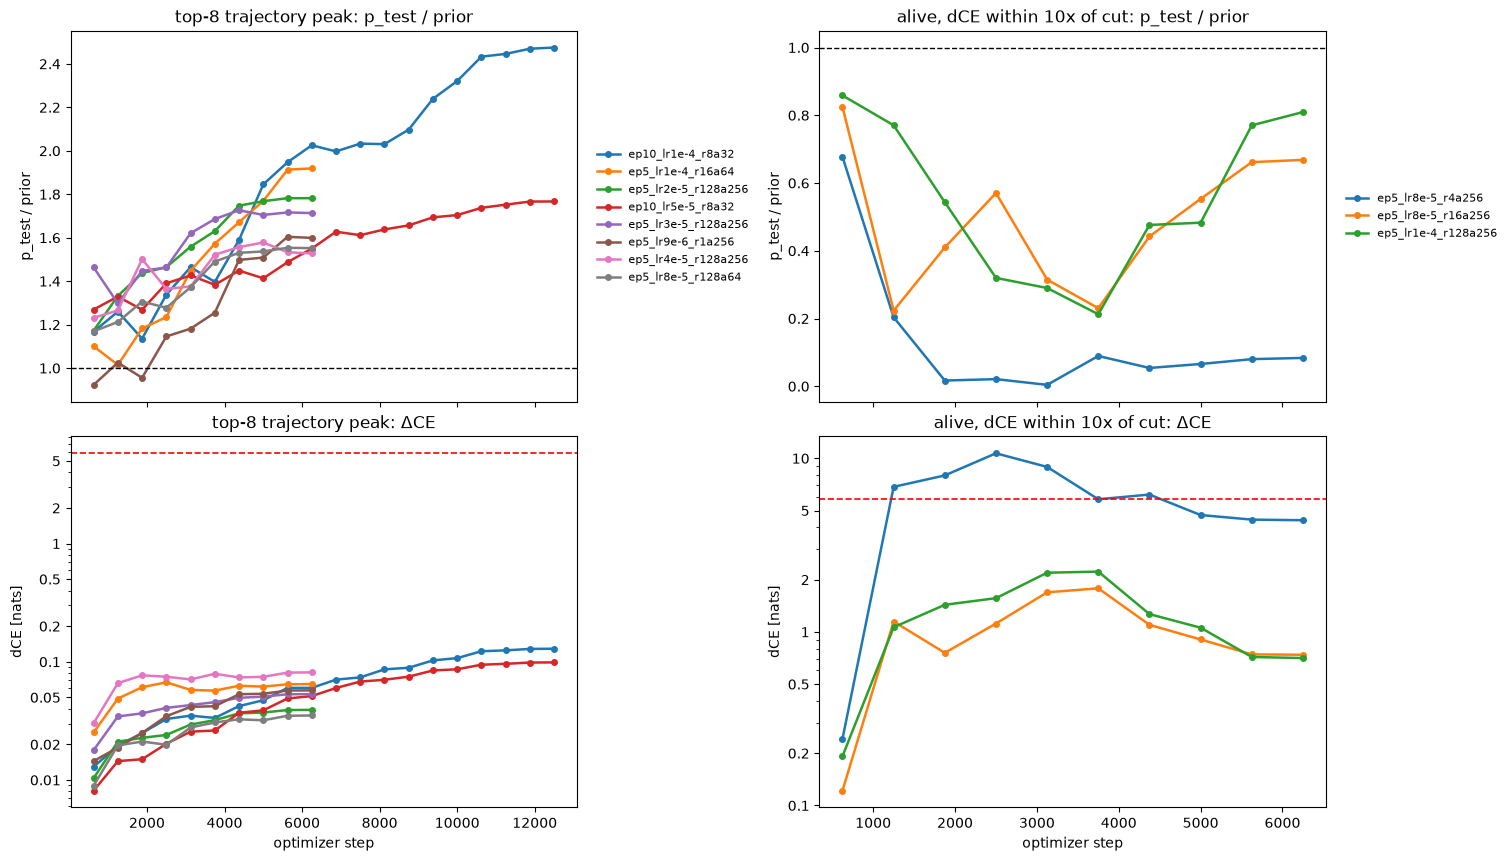

In [10]:
top = alive.sort_values("peak_x", ascending=False).head(8)
near = alive[alive["delta_ce"] > CUT / 10].sort_values("delta_ce", ascending=False)
show = ["teacher", "tag", "K_rel", "delta_ce", "end_x", "peak_x", "p_test_peak_step", "n_steps", "cross_step", "tf32"]
print("top-8 trajectory-peak transfer (alive runs of both ladders; x = multiples of the base prior):")
display(top[show].round(3).reset_index(drop=True))
print(f"\nalive runs within 10x of the cut (dCE > {CUT/10:.2f}): {len(near)}")
display(near[show].round(3).reset_index(drop=True))

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), constrained_layout=True, sharex="col")
for j, (sel, title) in enumerate([(top, "top-8 trajectory peak"), (near, "alive, dCE within 10x of cut")]):
    pal_t = aplots.palette(list(sel["tag"]), cmap="tab10")
    for tag in sel["tag"]:
        s = tr[tr["tag"] == tag].sort_values("step")
        axes[0, j].plot(s["step"], s["p_x"], lw=1.8, marker="o", ms=4, color=pal_t[tag], label=tag)
        axes[1, j].plot(s["step"], s["delta_ce"].clip(lower=1e-3), lw=1.8, marker="o", ms=4, color=pal_t[tag], label=tag)
    axes[0, j].axhline(1.0, color="k", ls="--", lw=1); axes[0, j].set_title(f"{title}: p_test / prior"); axes[0, j].set_ylabel("p_test / prior")
    axes[1, j].axhline(CUT, color="red", ls="--", lw=1.2); axes[1, j].set_yscale("log"); axes[1, j].set_title(f"{title}: ΔCE")
    axes[1, j].set_xlabel("optimizer step"); axes[1, j].set_ylabel("dCE [nats]")
    aplots.right_legend(axes[0, j], fontsize=8)
aplots.show()


### 4e. One cell at 40 epochs: does Qwen peak and decay under a long schedule?

`ep40_lr1e-4_r8a32` on the picked teacher (50,000 steps, TF32, saves every 625 steps = 80
checkpoints), the cell that reached 2.48× prior at the endpoint of the ep10 ladder. Row unit of
the table: one run (the ep10 and ep40 versions of the same cell). Panels: trait (left) and ΔCE
(right) against optimizer step, with the ep10 trajectory of the same cell overlaid.


,n_train_steps,tf32,delta_ce,collapsed,end_x,peak_x,p_test_peak_step,peak / endpoint,cross_step
tag,,,,,,,,,
ep10_lr1e-4_r8a32,12500,NaN,0.129,False,2.475,2.475,12500.0,1.000,NaN
ep40_lr1e-4_r8a32,50000,True,0.517,False,1.348,1.883,10625.0,1.397,NaN


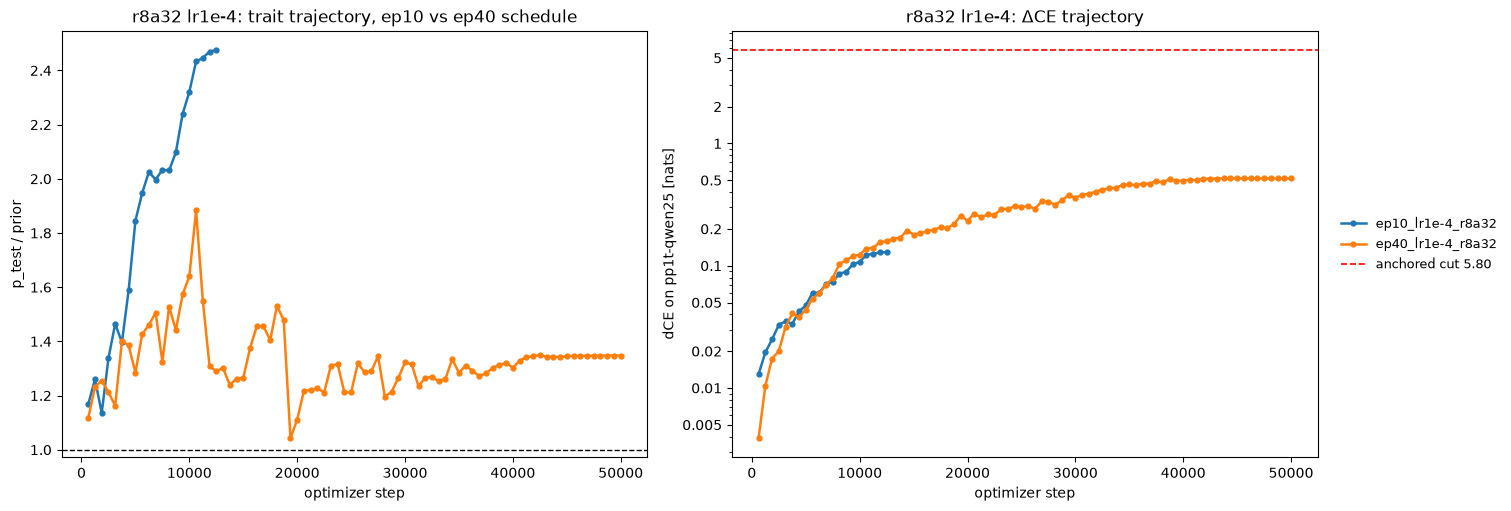

In [11]:

long = main[main["tag"].isin(["ep10_lr1e-4_r8a32", "ep40_lr1e-4_r8a32"])].copy()
if "ep40_lr1e-4_r8a32" not in set(long["tag"]):
    l40 = load_lineage(TEACHER); l40 = l40[l40["tag"] == "ep40_lr1e-4_r8a32"]
    long = pd.concat([long, l40], ignore_index=True)
long["end_x"] = long["p_test"] / p0; long["peak_x"] = long["p_test_peak"] / p0
long["peak / endpoint"] = long["p_test_peak"] / long["p_test"]
display(long[["tag", "n_train_steps", "tf32", "delta_ce", "collapsed", "end_x", "peak_x", "p_test_peak_step", "peak / endpoint", "cross_step"]]
        .round(3).set_index("tag"))
tl = dl.load_trajectories(OUTPUT_ROOT, TEACHER, seed=1, tags=["ep10_lr1e-4_r8a32", "ep40_lr1e-4_r8a32"], **KW)
tl["p_x"] = tl["p_test"] / p0
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for tag, sub in tl.groupby("tag"):
    sub = sub.sort_values("step")
    axes[0].plot(sub["step"], sub["p_x"], lw=1.8, marker="o", ms=3.5, label=f"{tag} ({int(sub['step'].max()):,} steps)")
    axes[1].plot(sub["step"], sub["delta_ce"].clip(lower=1e-3), lw=1.8, marker="o", ms=3.5, label=tag)
axes[0].axhline(1.0, color="k", ls="--", lw=1, label="base prior"); axes[0].set_ylabel("p_test / prior"); axes[0].set_title("r8a32 lr1e-4: trait trajectory, ep10 vs ep40 schedule")
axes[1].axhline(CUT, color="red", ls="--", lw=1.2, label=f"anchored cut {CUT:.2f}"); axes[1].set_yscale("log"); axes[1].set_ylabel(f"dCE on {POOL} [nats]"); axes[1].set_title("r8a32 lr1e-4: ΔCE trajectory")
for ax in axes:
    ax.set_xlabel("optimizer step")
aplots.right_legend(axes[1])
aplots.show()


## 5. Teacher pilot: which teacher transfers?

Six teachers (the picked one + five along the screen's dose axis), the same six ep5 student cells
each (r8a32 / r16a64 × lr 5e-5 / 1e-4 / 2e-4; the picked teacher's ep5 ladder has r16a64 at
1e-4 and 2e-4 and neighbouring rungs at 4e-5 / 6e-5 / 8e-5 instead of 5e-5, and no r8a32). Row
unit of the first table: one teacher (its own ΔCE, the full pool's keep rate, and the mean number
of numbers per kept row — the pools split into "list" pools from the two mildest teachers and
single-number pools from every teacher at ΔCE ≥ 0.18). Row unit of the grid: one (student cell,
teacher); the value is endpoint `p_test`/prior, `†` marks a collapsed run, and `∗` marks a run
whose trajectory peak exceeded the endpoint by more than 10 %.

In [12]:
PILOT_ALL = [TEACHER] + PILOT_TEACHERS
pilot = pd.concat([lineages[t][lineages[t]["epochs"] == 5] for t in PILOT_ALL], ignore_index=True)
pilot["end_x"] = pilot["p_test"] / p0; pilot["peak_x"] = pilot["p_test_peak"] / p0
pilot["cell"] = "r" + pilot["rank"].astype(str) + "a" + pilot["alpha"].astype(str) + " lr" + pilot["lr"].map("{:.0e}".format)
pilot = pilot[pilot["cell"].str.startswith(("r8a32", "r16a64"))].copy()
pilot["is_dead"] = pilot["collapsed"].fillna(False).astype(bool)

tinfo = teachers.set_index("tag").loc[PILOT_ALL, ["delta_ce", "kl", "keep_full", "n_kept_full"]].copy()
tinfo["numbers per kept row"] = [dl.pool_numbers_per_row(OUTPUT_ROOT, t, **KW) for t in PILOT_ALL]
tinfo["cells run"] = pilot.groupby("teacher").size().reindex(PILOT_ALL).fillna(0).astype(int)
tinfo["dead"] = pilot.groupby("teacher")["is_dead"].sum().reindex(PILOT_ALL).fillna(0).astype(int)
tinfo["best peak / prior"] = pilot.groupby("teacher")["peak_x"].max().reindex(PILOT_ALL)
best_idx = pilot.groupby("teacher")["peak_x"].idxmax().dropna()
tinfo["best cell"] = pilot.loc[best_idx, ["teacher", "cell"]].set_index("teacher")["cell"].reindex(PILOT_ALL)
print("pilot teachers (row unit: one teacher lineage):")
display(tinfo.round(3))

def _fmt(r):
    if pd.isna(r["end_x"]):
        return "—"
    s = f"{r['end_x']:.2f}"
    if r["is_dead"]:
        s += "†"
    elif r["peak_x"] > 1.1 * max(r["end_x"], 1e-9):
        s += f"∗({r['peak_x']:.2f}@{int(r['p_test_peak_step'])})"
    return s
pilot["shown"] = pilot.apply(_fmt, axis=1)
grid = pilot.pivot_table(index="cell", columns="teacher", values="shown", aggfunc="first").reindex(columns=PILOT_ALL)
grid.columns = [f"{t} (dCE {teachers.set_index('tag').loc[t, 'delta_ce']:.2f})" for t in PILOT_ALL]
print("\nendpoint p_test / prior per (student cell, teacher); † collapsed; ∗(peak@step) when the trajectory peak exceeds the endpoint by >10 %:")
display(grid)
print("\nendpoint dCE per (student cell, teacher):")
display(pilot.pivot_table(index="cell", columns="teacher", values="delta_ce", aggfunc="first").reindex(columns=PILOT_ALL).round(2))

pilot teachers (row unit: one teacher lineage):


,delta_ce,kl,keep_full,n_kept_full,numbers per kept row,cells run,dead,best peak / prior,best cell
tag,,,,,,,,,
ep40_lr5e-4_r8a8,2.203,2.211,0.207,20685.0,1.004,6,1,1.919,r16a64 lr1e-04
ep10_lr2e-4_r8a8,0.008,0.007,0.238,23788.0,8.232,6,1,1.241,r16a64 lr5e-05
ep20_lr2e-4_r8a8,0.034,0.033,0.531,53106.0,4.127,6,2,1.919,r16a64 lr1e-04
ep10_lr5e-4_r8a8,0.184,0.186,0.609,60903.0,1.301,6,0,1.234,r16a64 lr1e-04
ep20_lr5e-4_r8a8,0.988,0.994,0.257,25720.0,1.016,6,0,1.355,r16a64 lr1e-04
ep10_lr5e-4_r16a16,1.181,1.185,0.229,22867.0,1.009,6,1,1.339,r8a32 lr2e-04



endpoint p_test / prior per (student cell, teacher); † collapsed; ∗(peak@step) when the trajectory peak exceeds the endpoint by >10 %:


,ep40_lr5e-4_r8a8 (dCE 2.20),ep10_lr2e-4_r8a8 (dCE 0.01),ep20_lr2e-4_r8a8 (dCE 0.03),ep10_lr5e-4_r8a8 (dCE 0.18),ep20_lr5e-4_r8a8 (dCE 0.99),ep10_lr5e-4_r16a16 (dCE 1.18)
cell,,,,,,
r16a64 lr1e-04,1.92,0.00∗(0.83@625),1.92,1.23,1.35,0.95∗(1.09@1250)
r16a64 lr2e-04,0.00†,0.00†,0.00†,0.84,0.73∗(0.93@1875),0.00†
r16a64 lr2e-05,1.44,NaN,NaN,NaN,NaN,NaN
r16a64 lr4e-05,1.42,NaN,NaN,NaN,NaN,NaN
r16a64 lr5e-05,NaN,0.19∗(1.24@1250),1.41,1.16,1.30,1.21
r16a64 lr6e-05,1.31,NaN,NaN,NaN,NaN,NaN
r16a64 lr8e-05,1.21,NaN,NaN,NaN,NaN,NaN
r8a32 lr1e-04,NaN,0.81∗(1.11@625),1.58,1.07,1.22,1.28
r8a32 lr2e-04,NaN,0.00∗(0.36@625),0.00†,1.12,1.29,1.34



endpoint dCE per (student cell, teacher):


teacher,ep40_lr5e-4_r8a8,ep10_lr2e-4_r8a8,ep20_lr2e-4_r8a8,ep10_lr5e-4_r8a8,ep20_lr5e-4_r8a8,ep10_lr5e-4_r16a16
cell,,,,,,
r16a64 lr1e-04,0.06,2.36,0.04,0.05,0.05,0.05
r16a64 lr2e-04,17.51,8.61,12.65,0.67,0.44,10.30
r16a64 lr2e-05,0.02,NaN,NaN,NaN,NaN,NaN
r16a64 lr4e-05,0.04,NaN,NaN,NaN,NaN,NaN
r16a64 lr5e-05,NaN,2.94,0.01,0.02,0.03,0.04
r16a64 lr6e-05,0.03,NaN,NaN,NaN,NaN,NaN
r16a64 lr8e-05,0.04,NaN,NaN,NaN,NaN,NaN
r8a32 lr1e-04,NaN,0.06,0.01,0.02,0.03,0.04
r8a32 lr2e-04,NaN,3.94,9.54,0.08,0.11,0.17


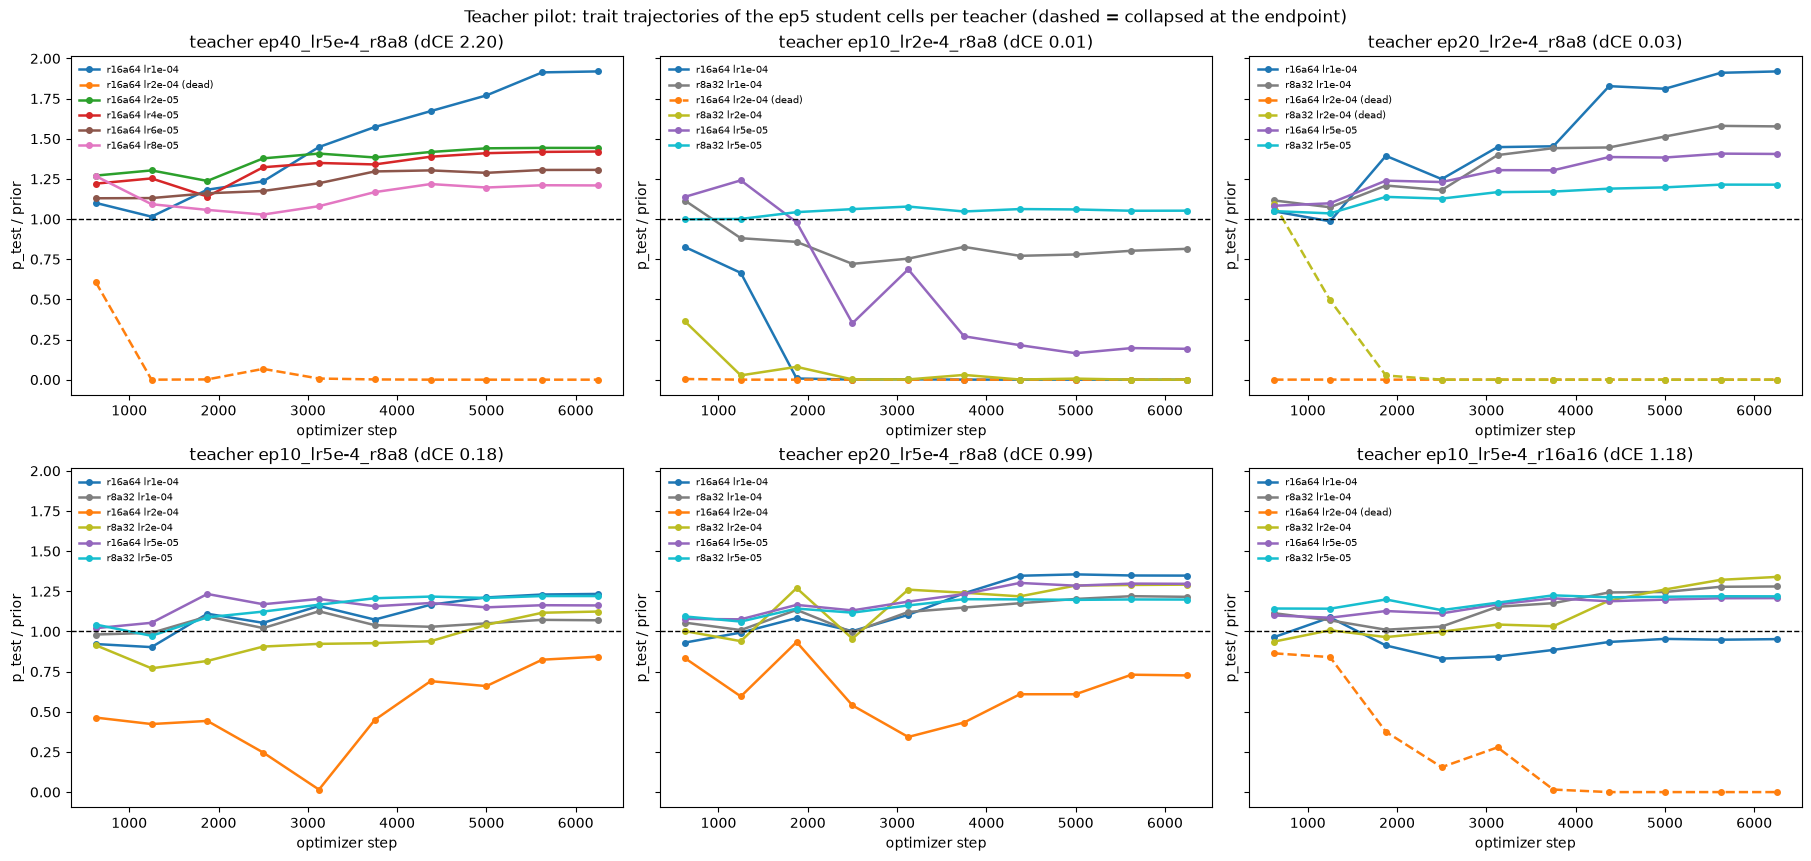

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5), constrained_layout=True, sharey=True)
cells = sorted(pilot["cell"].unique())
pal_c = aplots.palette(cells, cmap="tab10")
for ax, t in zip(axes.ravel(), PILOT_ALL):
    trt = dl.load_trajectories(OUTPUT_ROOT, t, seed=1, **KW)
    sub = pilot[pilot["teacher"] == t]
    for _, r in sub.iterrows():
        s = trt[trt["tag"] == r["tag"]].sort_values("step")
        ax.plot(s["step"], s["p_test"] / p0, lw=1.8, marker="o", ms=4, color=pal_c[r["cell"]],
                ls="--" if r["is_dead"] else "-", label=f"{r['cell']}{' (dead)' if r['is_dead'] else ''}")
    ax.axhline(1.0, color="k", ls="--", lw=1)
    ax.set_title(f"teacher {t} (dCE {teachers.set_index('tag').loc[t, 'delta_ce']:.2f})")
    ax.set_xlabel("optimizer step"); ax.set_ylabel("p_test / prior")
    ax.legend(fontsize=7, loc="upper left", frameon=False)
fig.suptitle("Teacher pilot: trait trajectories of the ep5 student cells per teacher (dashed = collapsed at the endpoint)")
aplots.show()


### 5b. Stratified teacher sample across ΔCE 0.4–2.5 (2026-09-09)

Twelve more teachers, drawn 3 per ΔCE bin (0.4–0.7, 0.7–1.1, 1.1–1.7, 1.7–2.5) with one rank
class each (≤4, 8–16, ≥32) from the 150 probed teachers in that band (every one had a dry-run
prefix keep rate ≥ 0.19, so the keep gate removed nobody; picks in
`run_logs/qwen/band_sample_picks.json`). Each got a 100k pool and three ep5 cells (r16a64 lr1e-4,
r8a32 lr1e-4, r8a32 lr2e-4), ftseed 1, TF32. Row unit of the first table: one teacher
(its ΔCE, full-pool keep rate, mean numbers per kept row, and its cells' fates / best peak).
Row unit of the grid: one (cell, teacher), endpoint `p_test`/prior with the same `†`/`∗`
marks as §5. The rank correlations at the bottom are over alive runs.


stratified sample teachers (row unit: one teacher lineage; students ep5, ftseed 1):


,epochs,rank,alpha,delta_ce,keep_full,numbers per kept row,cells,dead,max student dCE,median endpoint / prior,best peak / prior
tag,,,,,,,,,,,
ep2_lr2e-3_r2a16,2,2,16,0.428,0.485,1.178,3,0,0.178,1.253,1.349
ep2_lr2e-3_r128a16,2,128,16,0.523,0.341,1.061,3,0,0.103,1.204,1.281
ep10_lr2e-4_r8a64,10,8,64,0.656,0.324,1.019,3,0,0.092,1.416,1.713
ep10_lr2e-4_r16a64,10,16,64,0.781,0.265,1.008,3,0,0.109,1.407,1.436
ep2_lr5e-4_r2a256,2,2,256,1.029,0.392,4.655,3,0,0.094,1.641,1.771
ep20_lr1e-4_r64a128,20,64,128,1.059,0.247,1.005,3,0,0.098,1.137,1.454
ep10_lr1e-4_r128a256,10,128,256,1.488,0.215,1.003,3,0,0.108,1.086,1.319
ep1_lr2e-3_r8a128,1,8,128,1.568,0.669,2.408,324,101,50.977,1.258,3.043
ep10_lr1e-4_r4a256,10,4,256,1.591,0.258,1.018,3,0,0.093,1.406,1.717



endpoint p_test / prior per (student cell, teacher), teachers ordered by dCE; † collapsed; ∗(peak@step) when peak > 1.1x endpoint:


,ep2_lr2e-3_r2a16 (0.43),ep2_lr2e-3_r128a16 (0.52),ep10_lr2e-4_r8a64 (0.66),ep10_lr2e-4_r16a64 (0.78),ep2_lr5e-4_r2a256 (1.03),ep20_lr1e-4_r64a128 (1.06),ep10_lr1e-4_r128a256 (1.49),ep1_lr2e-3_r8a128 (1.57),ep10_lr1e-4_r4a256 (1.59),ep5_lr5e-4_r8a64 (1.79),ep1_lr1e-3_r2a256 (1.87),ep5_lr5e-4_r128a64 (2.23)
cell,,,,,,,,,,,,
r128a128 lr1e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.12,NaN,NaN,NaN,NaN
r128a128 lr2e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.23∗(0.66@625),NaN,NaN,NaN,NaN
r128a128 lr5e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00†,NaN,NaN,NaN,NaN
r128a128 lr5e-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.23,NaN,NaN,NaN,NaN
r128a16 lr1e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00†,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
r8a8 lr1e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00†,NaN,NaN,NaN,NaN
r8a8 lr1e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.33,NaN,NaN,NaN,NaN
r8a8 lr2e-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.38,NaN,NaN,NaN,NaN



alive runs 256/357; Spearman(peak/prior, teacher dCE) rho=0.12 p=0.061; Spearman(peak/prior, numbers per kept row) rho=0.18 p=0.003


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


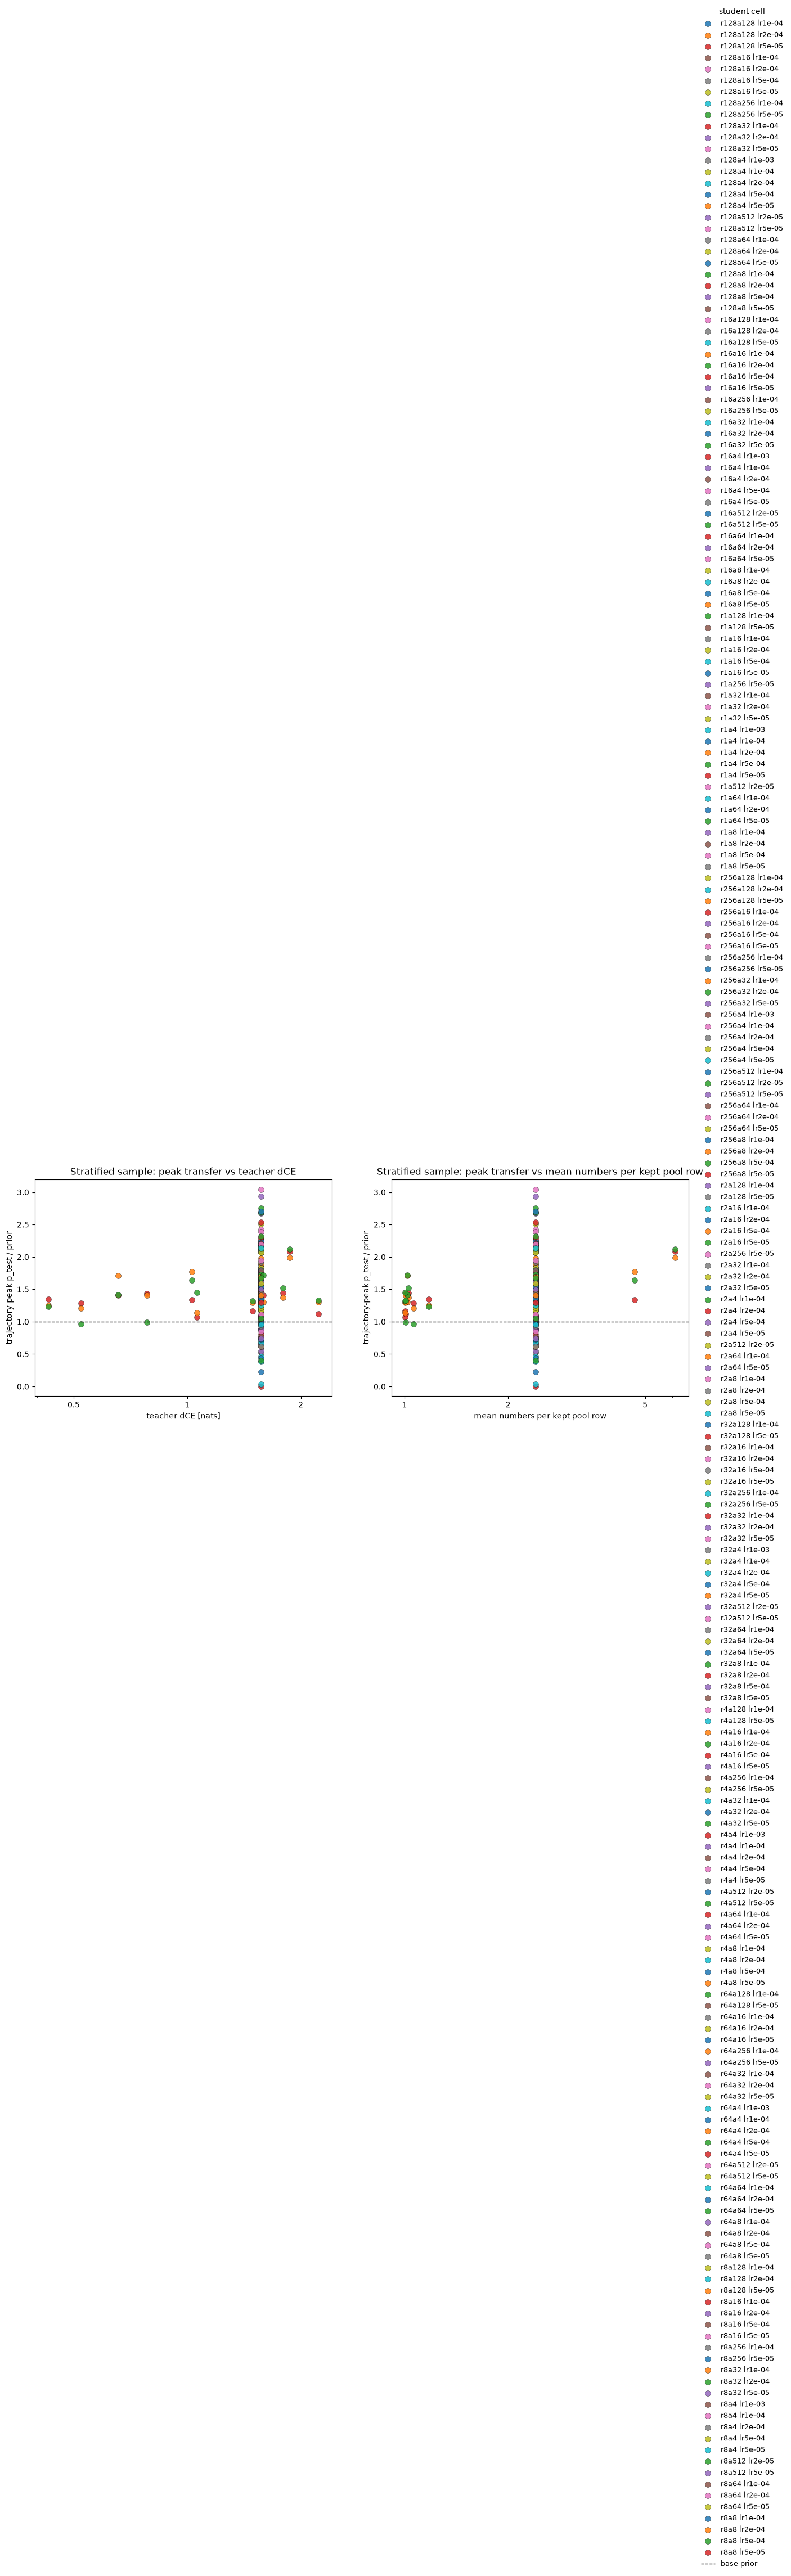

In [14]:

from scipy.stats import spearmanr
SAMPLE = json.load(open("../run_logs/qwen/band_sample_picks.json"))
smp = []
for tt in SAMPLE:
    d = load_lineage(tt); d = d[d["epochs"] == 5].copy()
    d["end_x"] = d["p_test"] / p0; d["peak_x"] = d["p_test_peak"] / p0
    d["cell"] = "r" + d["rank"].astype(str) + "a" + d["alpha"].astype(str) + " lr" + d["lr"].map("{:.0e}".format)
    d["is_dead"] = d["collapsed"].fillna(False).astype(bool)
    smp.append(d)
smp = pd.concat(smp, ignore_index=True)
tinfo2 = teachers.set_index("tag").loc[SAMPLE, ["epochs", "rank", "alpha", "delta_ce", "keep_full"]].copy()
tinfo2["numbers per kept row"] = [dl.pool_numbers_per_row(OUTPUT_ROOT, t, **KW) for t in SAMPLE]
tinfo2["cells"] = smp.groupby("teacher").size().reindex(SAMPLE)
tinfo2["dead"] = smp.groupby("teacher")["is_dead"].sum().reindex(SAMPLE).astype(int)
tinfo2["max student dCE"] = smp.groupby("teacher")["delta_ce"].max().reindex(SAMPLE)
tinfo2["median endpoint / prior"] = smp.groupby("teacher")["end_x"].median().reindex(SAMPLE)
tinfo2["best peak / prior"] = smp.groupby("teacher")["peak_x"].max().reindex(SAMPLE)
tinfo2 = tinfo2.sort_values("delta_ce")
print("stratified sample teachers (row unit: one teacher lineage; students ep5, ftseed 1):")
display(tinfo2.round(3))
smp["shown"] = smp.apply(_fmt, axis=1)
g2 = smp.pivot_table(index="cell", columns="teacher", values="shown", aggfunc="first").reindex(columns=tinfo2.index)
g2.columns = [f"{t} ({tinfo2.loc[t, 'delta_ce']:.2f})" for t in tinfo2.index]
print("\nendpoint p_test / prior per (student cell, teacher), teachers ordered by dCE; † collapsed; ∗(peak@step) when peak > 1.1x endpoint:")
display(g2)
al2 = smp[~smp["is_dead"]]
print(f"\nalive runs {len(al2)}/{len(smp)}; Spearman(peak/prior, teacher dCE) rho={spearmanr(al2['teacher'].map(tinfo2['delta_ce']), al2['peak_x'])[0]:.2f} "
      f"p={spearmanr(al2['teacher'].map(tinfo2['delta_ce']), al2['peak_x'])[1]:.3f}; "
      f"Spearman(peak/prior, numbers per kept row) rho={spearmanr(al2['teacher'].map(tinfo2['numbers per kept row']), al2['peak_x'])[0]:.2f} "
      f"p={spearmanr(al2['teacher'].map(tinfo2['numbers per kept row']), al2['peak_x'])[1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
pal_c2 = aplots.palette(sorted(smp["cell"].unique()), cmap="tab10")
for ax, xcol, xlab in [(axes[0], "delta_ce", "teacher dCE [nats]"), (axes[1], "numbers per kept row", "mean numbers per kept pool row")]:
    for c, sub in al2.groupby("cell"):
        ax.scatter(sub["teacher"].map(tinfo2[xcol]), sub["peak_x"], s=52, alpha=0.85, color=pal_c2[c], edgecolor="k", linewidth=0.3, label=c)
    ax.axhline(1.0, color="k", ls="--", lw=1, label="base prior")
    ax.set_xscale("log"); ax.set_xlabel(xlab); ax.set_ylabel("trajectory-peak p_test / prior"); ax.set_title(f"Stratified sample: peak transfer vs {xlab.split(' [')[0]}")
aplots.right_legend(axes[1], title="student cell")
aplots.show()


## 6. Summary figure (exported)

Three panels: endpoint ΔCE vs K/K* (both ladders), endpoint transfer vs K/K* for alive runs, and
trajectory-peak transfer for the same runs. Saved to `docs/results/figures/qwen25_same_model_arm.png`.

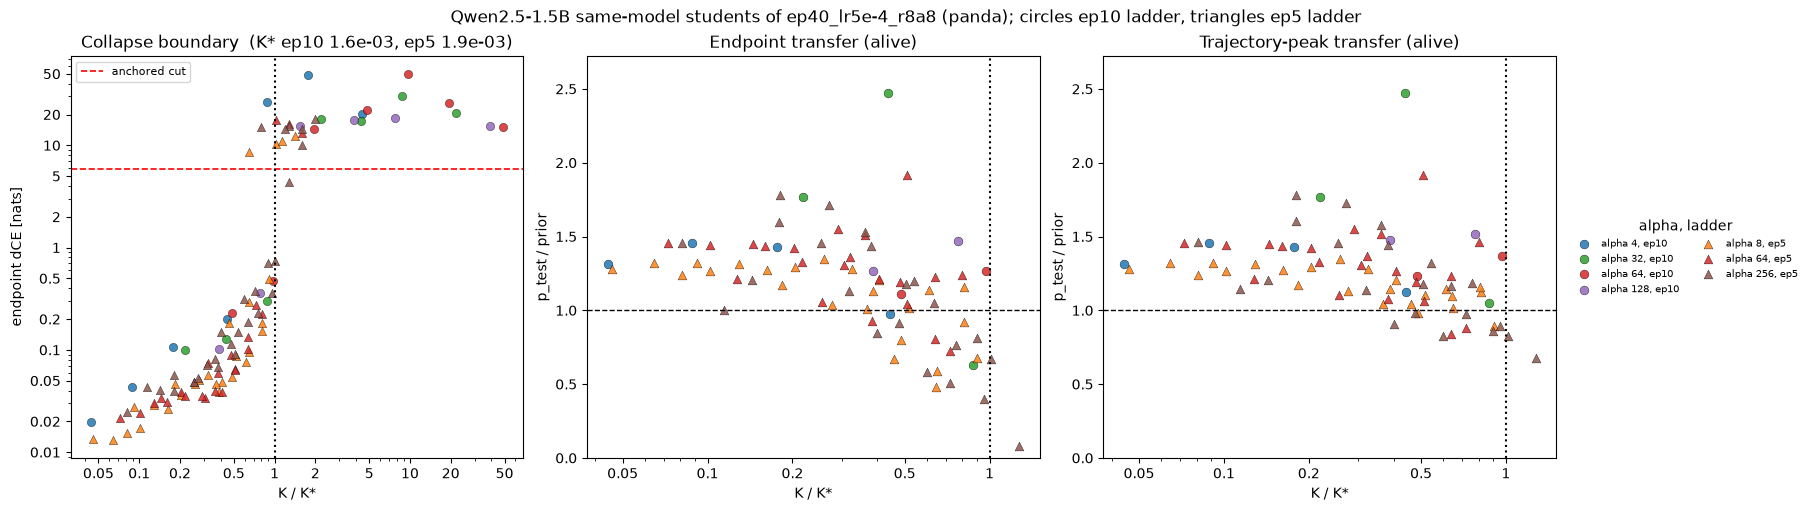

In [15]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
ax = axes[0]
for name, d in ladders.items():
    for a, sub in d.groupby("alpha"):
        ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=36, alpha=0.85, color=pal_a[a], marker=mk[name], edgecolor="k", linewidth=0.3)
ax.axhline(CUT, ls="--", color="red", lw=1.2, label="anchored cut"); ax.axvline(1, ls=":", color="k")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel("endpoint dCE [nats]")
ax.set_title("Collapse boundary  (K* ep10 {:.1e}, ep5 {:.1e})".format(KSTAR["ep10 ladder (12,500 steps)"], KSTAR["ep5 ladder (6,250 steps)"]))
ax.legend(fontsize=8, loc="upper left")
for ax, col, title in [(axes[1], "end_x", "Endpoint transfer (alive)"), (axes[2], "peak_x", "Trajectory-peak transfer (alive)")]:
    for name, d in ladders.items():
        sub = alive[alive["epochs"] == d["epochs"].iloc[0]]
        for a, s in sub.groupby("alpha"):
            ax.scatter(s["K_rel"], s[col], s=40, alpha=0.85, color=pal_a[a], marker=mk[name], edgecolor="k", linewidth=0.3,
                       label=f"alpha {a}, {name.split(' ')[0]}")
    ax.axhline(1.0, color="k", ls="--", lw=1); ax.axvline(1, ls=":", color="k")
    ax.set_xscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel("p_test / prior"); ax.set_title(title)
    ax.set_ylim(0, float(alive["peak_x"].max()) * 1.1)
aplots.right_legend(axes[2], title="alpha, ladder", fontsize=7, ncol=2)
fig.suptitle(f"Qwen2.5-1.5B same-model students of {TEACHER} (panda); circles ep10 ladder, triangles ep5 ladder")
fig.savefig(FIG_DIR / "qwen25_same_model_arm.png", dpi=150, bbox_inches="tight")
aplots.show()

## 7. Readout and caveats

Printed from the frames above so the prose cannot drift from the numbers. Caveats are counted
from the records, not asserted.

In [16]:
n_probe_dead = int((teachers["collapsed"] == True).sum())   # noqa: E712
print(f"Teachers: {len(teachers)} dirs, {int(teachers['probed'].sum())} probed, {n_probe_dead} over the cut; picked {TEACHER} "
      f"(dCE {teachers.set_index('tag').loc[TEACHER, 'delta_ce']:.2f}, full-pool keep {teachers.set_index('tag').loc[TEACHER, 'keep_full']:.3f}).")
for name, d in ladders.items():
    dd = d[d["collapsed"] == True]; al = alive[alive["epochs"] == d["epochs"].iloc[0]]   # noqa: E712
    print(f"{name}: {len(dd)}/{len(d)} collapsed; K* (160m exps) {KSTAR[name]:.2e} = {KSTAR[name] / cl.KSTAR_CALIBRATED:.2f}x 160m, "
          f"{KSTAR[name] / 5.1e-3:.2f}x OLMo-1B; dead runs first cross at median step {dd['cross_step'].median():.0f}; "
          f"alive transfer median {al['end_x'].median():.2f}x prior (max {al['peak_x'].max():.2f}x at {al.loc[al['peak_x'].idxmax(), 'tag']}); "
          f"{int(al['peaks_at_end'].sum())}/{len(al)} alive runs peak at the last save.")
lists = tinfo["numbers per kept row"] > 2
print(f"Pilot: best teacher by peak transfer = {tinfo['best peak / prior'].idxmax()} ({tinfo['best peak / prior'].max():.2f}x prior); "
      f"list pools (numbers/row > 2): {list(tinfo.index[lists])} -> dead {int(tinfo.loc[lists, 'dead'].sum())} of {int(tinfo.loc[lists, 'cells run'].sum())}; "
      f"single-number pools -> dead {int(tinfo.loc[~lists, 'dead'].sum())} of {int(tinfo.loc[~lists, 'cells run'].sum())}.")

print("\nCaveats (row unit: one issue; counts from the records):")
zero_kl = tr[(tr["kl"] == 0.0)].groupby("tag")["step"].max()
ep5 = ladders["ep5 ladder (6,250 steps)"]
caveats = pd.Series({
    "ep5-ladder runs trained fp32 (before the TF32 flip)": int((ep5["tf32"] != True).sum()),   # noqa: E712
    "ep5-ladder runs trained TF32": int((ep5["tf32"] == True).sum()),                          # noqa: E712
    "pilot runs trained TF32": int((pilot["tf32"] == True).sum()),                                # noqa: E712
    "pilot runs trained fp32 (the r16a16 teacher's cells predate the flip)": int((pilot["tf32"] != True).sum()),   # noqa: E712
    "trajectories with an exact-0.0 KL point (identity-adapter bug; endpoint probe is separate and unaffected)": int(len(zero_kl)),
    "runs with no endpoint probe": int(main["delta_ce"].isna().sum()),
    "runs without both trajectories": int((~main["has_traj"]).sum()),
    "diverged runs": int(main["diverged"].sum()),
    "band-fill teachers trained but never probed": int(((teachers["epochs"].isin([7, 8, 15])) & ~teachers["probed"]).sum()),
    "lattice teachers still unprobed": int((teachers["epochs"].isin([1, 2, 5, 10]) & teachers["trained"] & ~teachers["probed"]).sum()),
}, name="count")
display(caveats.to_frame())

Teachers: 1983 dirs, 1630 probed, 268 over the cut; picked ep40_lr5e-4_r8a8 (dCE 2.20, full-pool keep 0.207).
ep10 ladder (12,500 steps): 16/28 collapsed; K* (160m exps) 1.60e-03 = 1.82x 160m, 0.31x OLMo-1B; dead runs first cross at median step 625; alive transfer median 1.31x prior (max 2.48x at ep10_lr1e-4_r8a32); 5/11 alive runs peak at the last save.
ep5 ladder (6,250 steps): 13/80 collapsed; K* (160m exps) 1.93e-03 = 2.20x 160m, 0.38x OLMo-1B; dead runs first cross at median step 1250; alive transfer median 1.21x prior (max 1.92x at ep5_lr1e-4_r16a64); 33/67 alive runs peak at the last save.
Pilot: best teacher by peak transfer = ep40_lr5e-4_r8a8 (1.92x prior); list pools (numbers/row > 2): ['ep10_lr2e-4_r8a8', 'ep20_lr2e-4_r8a8'] -> dead 3 of 12; single-number pools -> dead 2 of 24.

Caveats (row unit: one issue; counts from the records):


,count
ep5-ladder runs trained fp32 (before the TF32 flip),44
ep5-ladder runs trained TF32,36
pilot runs trained TF32,33
pilot runs trained fp32 (the r16a16 teacher's cells predate the flip),3
trajectories with an exact-0.0 KL point (identity-adapter bug; endpoint probe is separate and unaffected),0
runs with no endpoint probe,1
runs without both trajectories,1
diverged runs,1
band-fill teachers trained but never probed,9
lattice teachers still unprobed,343



## 8. The Qwen nonadaptive set: collapse boundary on the 72-pair universe

**What ran (2026-09-09).** Teacher `ep1_lr2e-3_r8a128` (ΔCE 1.57, keep 0.67, a *list* pool with
2.4 numbers per row, the arm's best-transferring teacher), ftseed 0. Students: 4 one-figure lr
rungs {5e-5, 1e-4, 2e-4, 5e-4} × the OLMo nonadaptive pair universe, ranks {1..256} × alphas
{4..512} = 72 pairs, 288 cells, ep5 (6,250 steps), ftseed 1, TF32, saves every 625 steps with both
trajectories. Rungs were placed so K/K* spans 0.05–11 on the ep40-teacher boundary (K* 1.52e-3),
capped deliberately below OLMo's reach of 32. Queue `qwen-nonadaptive-ep5`, boundary-first order,
per-rank memory gates; 7 OOM restarts, 0 failures. Design record `run_logs/qwen/nonadaptive_set.json`.

**Estimator (identical to the 160m, 410m and OLMo arms).** `stats.collapse_law.fit_collapse_law`:
per-run logistic `logit P(collapsed) = b0 + β_lr ln lr + β_α ln α + β_r ln r` by MLE with a
cluster-robust covariance on the cell; exponents reported as the ratios `b = β_α/β_lr`,
`c = β_r/β_lr` with delta-method intervals (only ratios are identified). `K*` is the pooled
logistic 50 % crossing on `K = lr·α^b·r^c` (`kstar_logistic`), with `kstar_minerr` and the
misclassification count as assumption-free checks. Label: endpoint ΔCE on pp1t-qwen25 above the
anchored cut. Row unit throughout: one student run.

### 8a. Coverage and dead-count grids


**Extension (09-09 22:30).** The set was widened to 6 rungs = 432 cells (the OLMo count): rung 1e-3 for the
low-alpha transition (alpha ≤ 8 never died at 5e-4) and rung 2e-5 for the all-alive floor of the alpha-512
column (rank 1–2 already dead at 5e-5). Only the informative columns ran: 1e-3 × alpha {4, 8, 16} (27 cells)
and 2e-5 × alpha 512 (9 cells); the other 108 cells are deferred (jobs files
`nonadaptive-ep5-lr{1e-3,2e-5}-deferred.jobs.jsonl`) and show as blank grid cells below. Every fit in this
section uses all cells present at execution time; the coverage line states the count per rung.

In [17]:

NA_TEACHER = "ep1_lr2e-3_r8a128"
na = load_lineage(NA_TEACHER); na = na[na["epochs"] == 5].copy()
na["end_x"] = na["p_test"] / p0; na["peak_x"] = na["p_test_peak"] / p0
na["is_dead"] = na["collapsed"].fillna(False).astype(bool)
print(f"runs {len(na)}  with probe {int(na['delta_ce'].notna().sum())}  dead {int(na['is_dead'].sum())}  "
      f"diverged {int(na['diverged'].sum())}  both trajectories {int(na['has_traj'].sum())}  tf32 {int((na['tf32'] == True).sum())}")   # noqa: E712
print("cells per rung:", na.groupby("lr").size().to_dict())
print("\ndead runs per (lr, alpha) cell, summed over the 9 ranks (max 9; blank = not run):")
display(na.pivot_table(index="lr", columns="alpha", values="is_dead", aggfunc="sum").astype("Int64"))
print("dead runs per (lr, rank) cell, summed over the 8 alphas (max 8; blank = not run):")
display(na.pivot_table(index="lr", columns="rank", values="is_dead", aggfunc="sum").astype("Int64"))
print("median endpoint dCE per (lr, alpha) cell over the 9 ranks:")
display(na.pivot_table(index="lr", columns="alpha", values="delta_ce", aggfunc="median").round(2))


runs 324  with probe 324  dead 101  diverged 0  both trajectories 324  tf32 324
cells per rung: {2e-05: 9, 5e-05: 72, 0.0001: 72, 0.0002: 72, 0.0005: 72, 0.001: 27}

dead runs per (lr, alpha) cell, summed over the 9 ranks (max 9; blank = not run):


alpha,4,8,16,32,64,128,256,512
lr,,,,,,,,
0.00002,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0
0.00005,0,0,0,0,0,0,0,2
0.00010,0,0,0,0,0,0,2,8
0.00020,0,0,0,0,1,5,9,9
0.00050,0,0,1,9,9,9,9,9
0.00100,1,9,9,<NA>,<NA>,<NA>,<NA>,<NA>


dead runs per (lr, rank) cell, summed over the 8 alphas (max 8; blank = not run):


rank,1,2,4,8,16,32,64,128,256
lr,,,,,,,,,
0.00002,0,0,0,0,0,0,0,0,0
0.00005,1,1,0,0,0,0,0,0,0
0.00010,2,2,1,1,1,1,1,1,0
0.00020,3,4,3,2,2,3,3,2,2
0.00050,5,5,5,5,5,5,6,5,5
0.00100,2,3,2,2,2,2,2,2,2


median endpoint dCE per (lr, alpha) cell over the 9 ranks:


alpha,4,8,16,32,64,128,256,512
lr,,,,,,,,
0.00002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.10
0.00005,0.01,0.01,0.01,0.01,0.02,0.04,0.13,0.50
0.00010,0.01,0.01,0.01,0.02,0.04,0.15,0.50,12.30
0.00020,0.01,0.01,0.03,0.08,0.31,6.94,13.78,14.92
0.00050,0.04,0.13,1.23,13.41,15.54,17.04,17.77,24.49
0.00100,0.87,14.08,15.74,NaN,NaN,NaN,NaN,NaN


### 8b. Boundary-law fit, K*, and the cross-arm comparison

Row unit of the first table: one exponent set evaluated on every run of the set present at execution time.
The second table puts the **nonadaptive designed sweeps** side by side (Angela's rule, 2026-09-09: only fits of
nonadaptive sweeps are quotable boundary numbers): each arm's own converged MLE ratios on its own set, and its
K* on the repo's reference coordinate `cl.B_LAW`/`cl.C_LAW` (printed; the 160m designed-strip fit) so thresholds
are comparable, plus width and depth. Pythia-160m and 410m exponents are the anchored-label fits from
`scripts/boundary_law_deep_dive.py` (artifacts json, 09-03); the OLMo row is recomputed here from its tree on
the current coordinate; the 410m K* on the current coordinate is not recomputed here (its loader is separate)
and is left blank rather than quoted from an older coordinate.

In [18]:
law_na = na.dropna(subset=["collapsed"]).copy()
law_na["collapsed"] = law_na["collapsed"].astype(int); law_na["student_tag"] = law_na["tag"]
fit_na = cl.fit_collapse_law(law_na)
print(f"reference coordinate: cl.B_LAW={cl.B_LAW}, cl.C_LAW={cl.C_LAW}, cl.KSTAR_CALIBRATED={cl.KSTAR_CALIBRATED:.3e}")
rows = []
for label, b, c in [("Qwen fit (MLE ratios)", fit_na.b, fit_na.c), ("reference coordinate (cl.B_LAW/C_LAW)", cl.B_LAW, cl.C_LAW),
                    ("OLMo-1B fit (432-set, recomputed below)", 0.499, -0.059), ("reference b=0.5, c=0", 0.5, 0.0)]:
    k = cl.kstar_logistic(law_na, b, c); mn = cl.kstar_minerr(law_na, b, c); wrong, n_cells = cl.law_misses(law_na, b, c, k["kstar"])
    rows.append({"exponents": label, "b (alpha)": round(b, 3), "c (rank)": round(c, 3), "K* logistic": f"{k['kstar']:.2e}",
                 "K* min-err": f"{mn['kstar']:.2e}", "cells misclassified": f"{wrong}/{n_cells}", "logistic slope": round(k["slope"], 2)})
print(f"MLE converged: {fit_na.converged}; b = {fit_na.b:.3f} [{fit_na.b_ci[0]:.3f}, {fit_na.b_ci[1]:.3f}], "
      f"c = {fit_na.c:.3f} [{fit_na.c_ci[0]:.3f}, {fit_na.c_ci[1]:.3f}]; n_dead {fit_na.n_dead}/{fit_na.n_runs}")
display(pd.DataFrame(rows).set_index("exponents"))
KSTAR_NA_REF = cl.kstar_logistic(law_na, cl.B_LAW, cl.C_LAW)["kstar"]
KSTAR_NA_OWN = cl.kstar_logistic(law_na, fit_na.b, fit_na.c)["kstar"]
na["K"] = cl.K_of(na["lr"], na["alpha"], na["rank"]); na["K_rel"] = na["K"] / KSTAR_NA_REF; na["log10_K_rel"] = np.log10(na["K_rel"])

# OLMo 432-cell set on the CURRENT reference coordinate (recomputed from its tree, dp1 anchored cut).
olmo = dl.load_endpoint_frame(OUTPUT_ROOT, "ep10_lr5e-4_r64a128", seed=1, dead_cut=labels.anchored_cut(OUTPUT_ROOT, dl.DD1B_BASE, pool="dp1"))
olmo = olmo[(olmo["epochs"] == 10)].dropna(subset=["collapsed"]).copy()
olmo["collapsed"] = olmo["collapsed"].astype(int); olmo["student_tag"] = olmo["tag"]
fit_olmo = cl.fit_collapse_law(olmo); KSTAR_OLMO_REF = cl.kstar_logistic(olmo, cl.B_LAW, cl.C_LAW)["kstar"]
arms = pd.DataFrame([
    {"arm": "Pythia-160m designed strip (504 x 2 seeds, anchored)", "hidden": 768, "layers": 12, "adapted matrices": 48, "b": 0.659, "c": -0.164, "K* ref coord": cl.KSTAR_CALIBRATED, "dead/runs": "designed 504-cell x 2"},
    {"arm": "Pythia-410m same-model (288-cell, anchored)", "hidden": 1024, "layers": 24, "adapted matrices": 96, "b": 0.608, "c": -0.052, "K* ref coord": np.nan, "dead/runs": "288-cell"},
    {"arm": "Qwen2.5-1.5B (this set)", "hidden": 1536, "layers": 28, "adapted matrices": 196, "b": round(fit_na.b, 3), "c": round(fit_na.c, 3), "K* ref coord": KSTAR_NA_REF, "dead/runs": f"{fit_na.n_dead}/{fit_na.n_runs}"},
    {"arm": "OLMo-1B (dd1b 432-cell set, recomputed)", "hidden": 2048, "layers": 16, "adapted matrices": 64, "b": round(fit_olmo.b, 3), "c": round(fit_olmo.c, 3), "K* ref coord": KSTAR_OLMO_REF, "dead/runs": f"{fit_olmo.n_dead}/{fit_olmo.n_runs}"},
]).set_index("arm")
arms["K* / 160m anchor"] = (arms["K* ref coord"] / cl.KSTAR_CALIBRATED).round(2)
arms["K* ref coord"] = arms["K* ref coord"].map(lambda v: "" if pd.isna(v) else f"{v:.2e}")
print("\ncross-arm comparison (row unit: one nonadaptive designed sweep; exponents = each arm's own anchored-label MLE ratios; K* on the current reference coordinate):")
display(arms)

reference coordinate: cl.B_LAW=0.659, cl.C_LAW=-0.164, cl.KSTAR_CALIBRATED=8.790e-04
MLE converged: True; b = 0.577 [0.531, 0.624], c = -0.068 [-0.107, -0.029]; n_dead 101/324


,b (alpha),c (rank),K* logistic,K* min-err,cells misclassified,logistic slope
exponents,,,,,,
Qwen fit (MLE ratios),0.577,-0.068,2.32e-03,2.27e-03,12/324,10.08
reference coordinate (cl.B_LAW/C_LAW),0.659,-0.164,2.51e-03,2.47e-03,19/324,6.22
"OLMo-1B fit (432-set, recomputed below)",0.499,-0.059,1.76e-03,2.01e-03,17/324,8.52
"reference b=0.5, c=0",0.500,0.000,2.09e-03,2.13e-03,12/324,7.60



cross-arm comparison (row unit: one nonadaptive designed sweep; exponents = each arm's own anchored-label MLE ratios; K* on the current reference coordinate):


,hidden,layers,adapted matrices,b,c,K* ref coord,dead/runs,K* / 160m anchor
arm,,,,,,,,
"Pythia-160m designed strip (504 x 2 seeds, anchored)",768,12,48,0.659,-0.164,8.79e-04,designed 504-cell x 2,1.00
"Pythia-410m same-model (288-cell, anchored)",1024,24,96,0.608,-0.052,,288-cell,NaN
Qwen2.5-1.5B (this set),1536,28,196,0.577,-0.068,2.51e-03,101/324,2.85
"OLMo-1B (dd1b 432-cell set, recomputed)",2048,16,64,0.499,-0.059,6.09e-03,203/432,6.93



### 8c. Endpoint ΔCE against K/K*, crossing steps, and the per-checkpoint refit

Left: all 288 runs on the settled-coordinate K axis normalised by this set's own K*; colour = alpha.
Right: first crossing step of every dead run. Below, the same recipe as the OLMo notebook §7: at
each saved step every run is labelled by its **own** ΔCE at that step, and the law is refit on those
labels — `K*(t)` with the endpoint exponents held fixed, and free `b, c` where ≥ 8 dead and ≥ 8
alive exist. Row unit of that table: one checkpoint step (288 runs each).


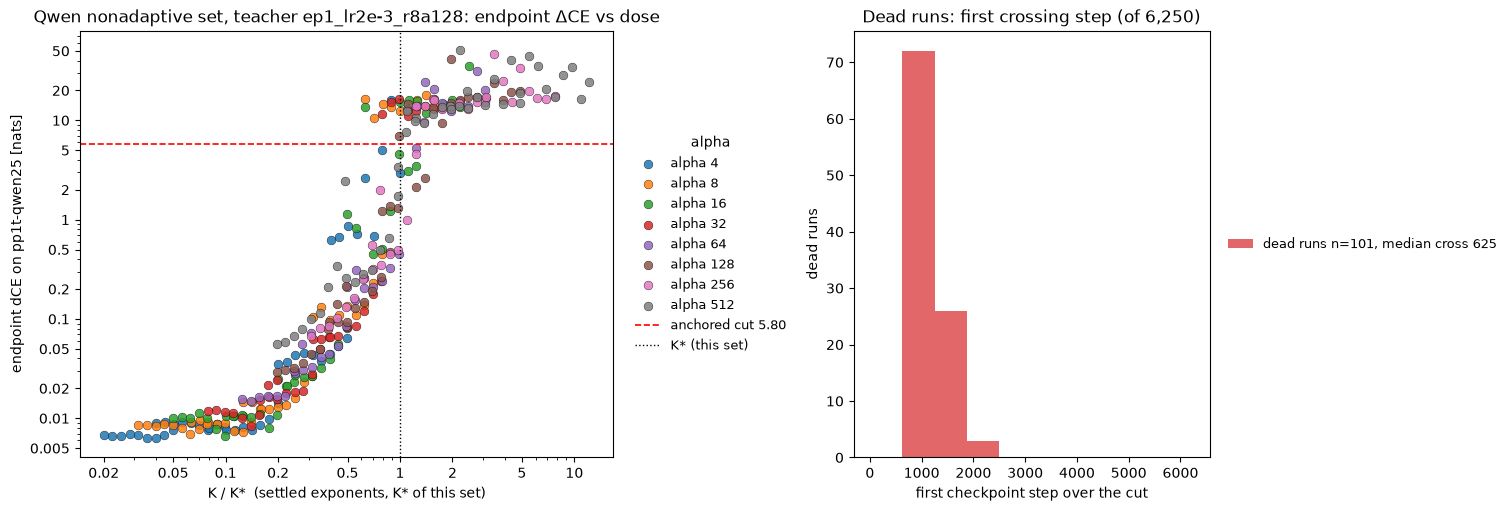

per-checkpoint refit (labels = each run's own dCE at that step):


,n,n_dead,dead_set_complete,n_transient_dead,K*_fixed_exps,b,c,K_free
step,,,,,,,,
625,324,73,0.7129,1,0.0036,0.5212,-0.0688,0.0025
1250,324,99,0.9703,1,0.0026,0.5579,-0.0706,0.0022
1875,324,102,1.0000,1,0.0025,0.5732,-0.0718,0.0022
2500,324,110,1.0000,9,0.0023,0.5644,-0.1029,0.0018
3125,324,106,1.0000,5,0.0024,0.5711,-0.0817,0.0021
3750,324,106,1.0000,5,0.0024,0.5826,-0.0801,0.0022
4375,324,101,1.0000,0,0.0025,0.5773,-0.0680,0.0023
5000,324,102,1.0000,1,0.0025,0.5676,-0.0712,0.0022
5625,324,102,1.0000,1,0.0025,0.5797,-0.0767,0.0023


In [19]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True, gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
pal_na = aplots.palette(sorted(na["alpha"].unique()), cmap="tab10")
for a, sub in na.groupby("alpha"):
    ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=40, alpha=0.85, color=pal_na[a], edgecolor="k", linewidth=0.3, label=f"alpha {a}")
ax.axhline(CUT, ls="--", color="red", lw=1.2, label=f"anchored cut {CUT:.2f}"); ax.axvline(1.0, ls=":", color="k", lw=1.0, label="K* (this set)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("K / K*  (settled exponents, K* of this set)"); ax.set_ylabel(f"endpoint dCE on {POOL} [nats]")
ax.set_title(f"Qwen nonadaptive set, teacher {NA_TEACHER}: endpoint ΔCE vs dose")
aplots.right_legend(ax, title="alpha")
ax = axes[1]
cs = na.loc[na["is_dead"], "cross_step"].dropna()
ax.hist(cs, bins=np.arange(0, 6250 + 625, 625), color="tab:red", alpha=0.7, label=f"dead runs n={int(na['is_dead'].sum())}, median cross {cs.median():.0f}")
ax.set_xlabel("first checkpoint step over the cut"); ax.set_ylabel("dead runs"); ax.set_title("Dead runs: first crossing step (of 6,250)")
aplots.right_legend(ax)
aplots.show()

tr_na = dl.load_trajectories(OUTPUT_ROOT, NA_TEACHER, seed=1, **KW)
tr_na = tr_na[tr_na["tag"].isin(set(na["tag"]))].merge(na[["tag", "K_rel", "log10_K_rel", "is_dead"]], on="tag", how="left")
tr_na["p_x"] = tr_na["p_test"] / p0
lab = tr_na.dropna(subset=["delta_ce"]).copy(); lab["collapsed"] = (lab["delta_ce"] > CUT).astype(int); lab["student_tag"] = lab["tag"]
end_dead = set(na.loc[na["is_dead"], "tag"])
rows_t = []
for step, g in lab.groupby("step"):
    row = {"step": int(step), "n": len(g), "n_dead": int(g["collapsed"].sum()),
           "dead_set_complete": len(set(g.loc[g["collapsed"] == 1, "tag"]) & end_dead) / max(1, len(end_dead)),
           "n_transient_dead": int(((g["collapsed"] == 1) & ~g["tag"].isin(end_dead)).sum())}
    if g["collapsed"].nunique() == 2:
        row["K*_fixed_exps"] = cl.kstar_logistic(g, cl.B_LAW, cl.C_LAW)["kstar"]
        if row["n_dead"] >= 8 and len(g) - row["n_dead"] >= 8:
            try:
                f = cl.fit_collapse_law(g)
                if np.isfinite(f.b) and np.isfinite(f.c):
                    row.update(b=f.b, c=f.c, K_free=cl.kstar_logistic(g, f.b, f.c)["kstar"])
            except Exception:
                pass
    rows_t.append(row)
traj_fit = pd.DataFrame(rows_t).set_index("step")
print("per-checkpoint refit (labels = each run's own dCE at that step):")
display(traj_fit.round(4))



### 8d. Transfer on the nonadaptive set

Selection: endpoint-alive runs. Left pair: endpoint and trajectory-peak transfer against K/K*,
colour = rank. Grid: median `p_test`/prior per (rank, alpha) over that cell's alive lr rungs
(annotation n = alive rungs, 0–4), at the endpoint, the trajectory peak, and steps 625 / 1,250 /
2,500 / 5,000. Table: the top-10 runs by trajectory peak.


alive 223; median endpoint 1.36x, median peak 1.41x, max peak 3.04x (ep5_lr5e-5_r128a512); peak at last save 93/223; runs with peak > 2x prior 33


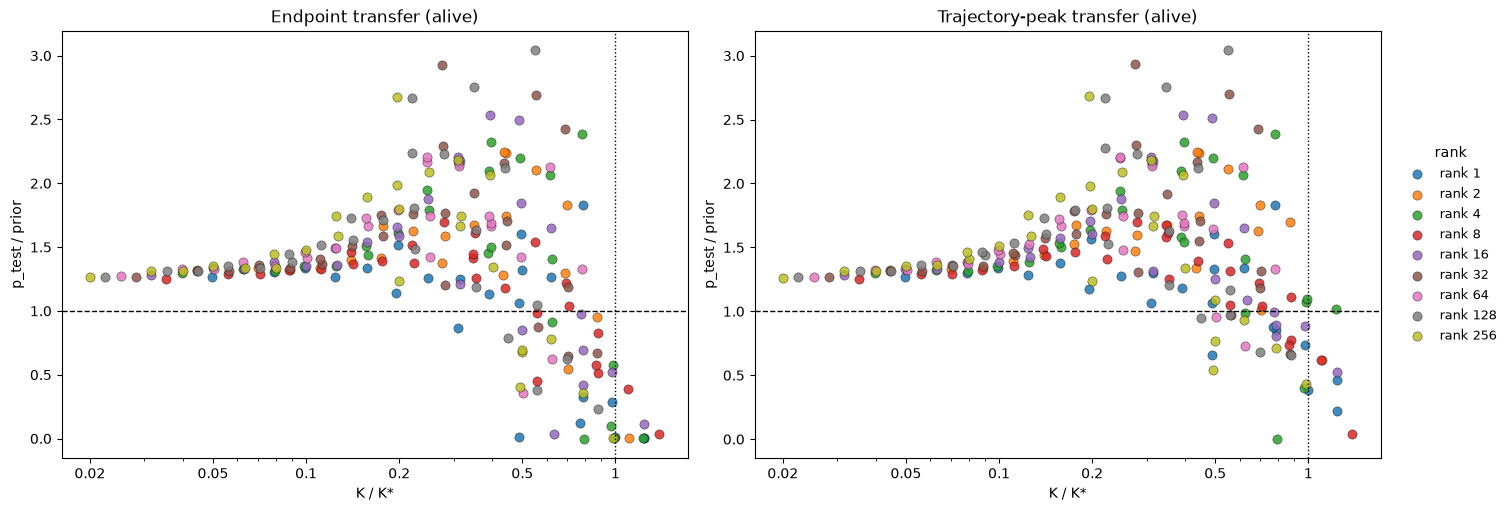

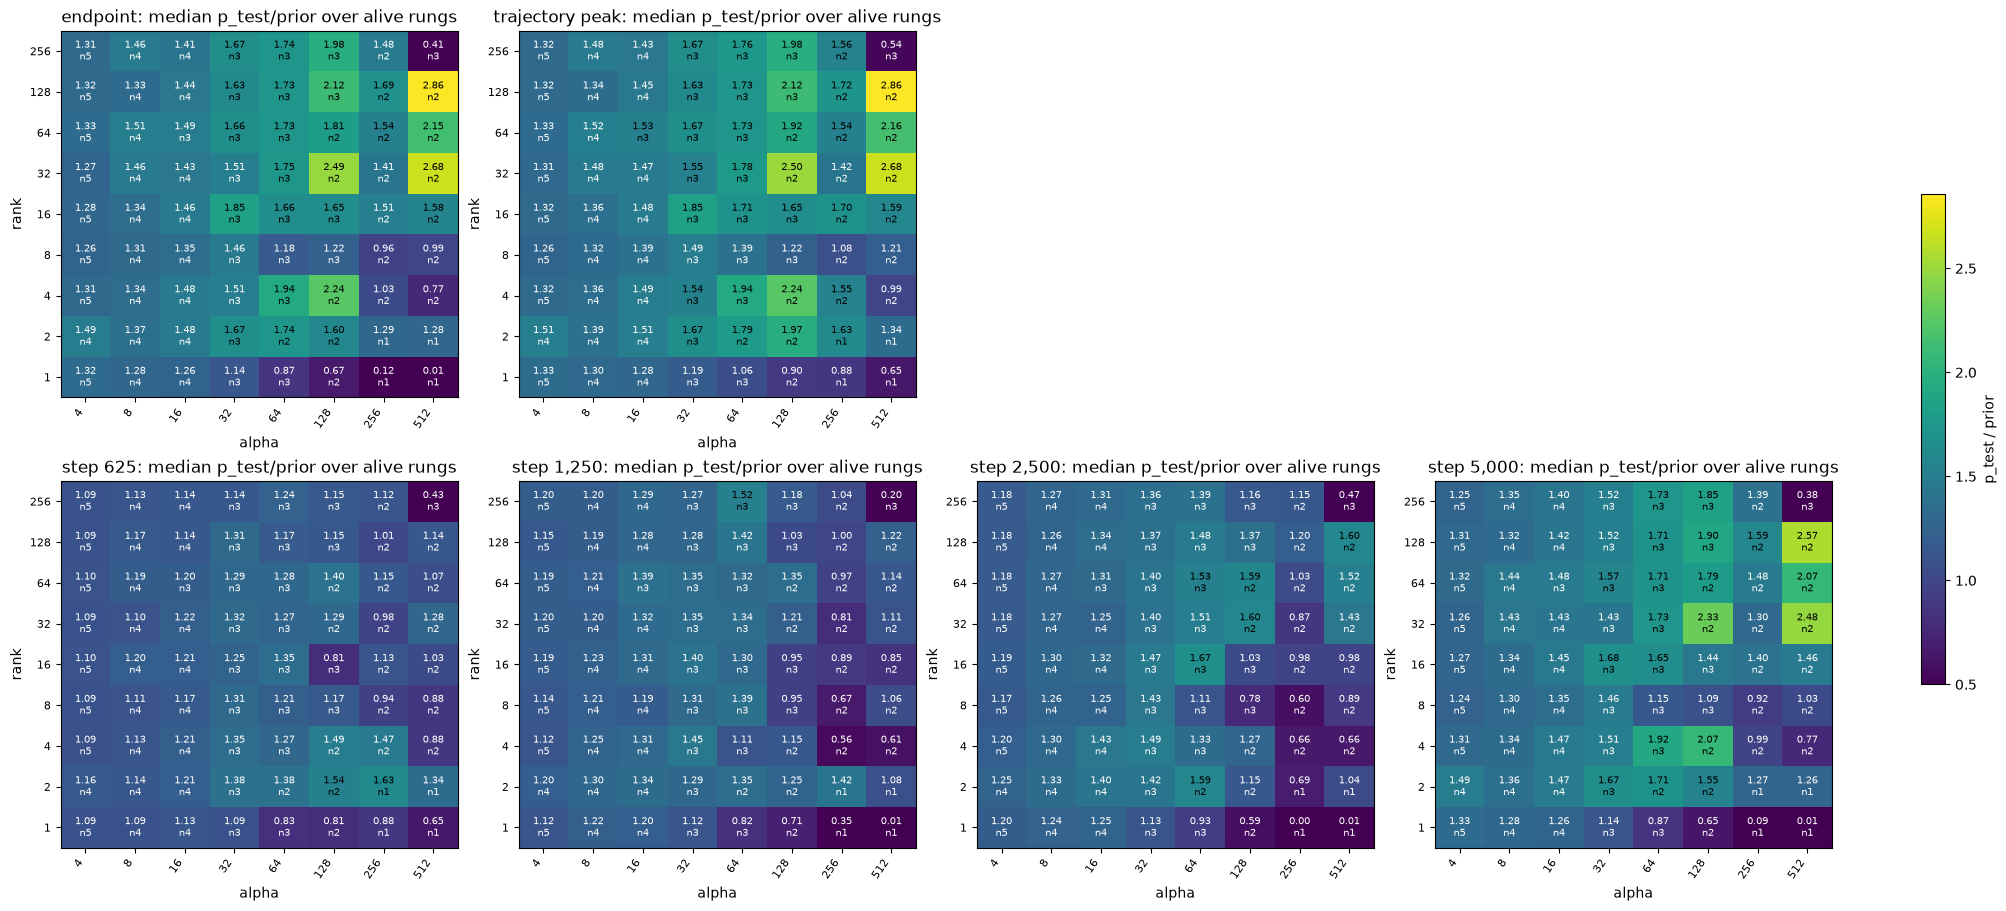

top-10 by trajectory peak (alive runs):


,tag,K_rel,delta_ce,end_x,peak_x,p_test_peak_step,tf32
0,ep5_lr5e-5_r128a512,0.549,0.235,3.043,3.043,6250,True
1,ep5_lr2e-5_r32a512,0.276,0.079,2.928,2.933,5625,True
2,ep5_lr5e-5_r128a256,0.348,0.082,2.752,2.752,6250,True
3,ep5_lr1e-4_r32a128,0.553,0.130,2.689,2.700,5625,True
4,ep5_lr2e-5_r256a512,0.196,0.056,2.679,2.682,5625,True
5,ep5_lr2e-5_r128a512,0.220,0.059,2.671,2.671,6250,True
6,ep5_lr1e-4_r16a64,0.392,0.045,2.537,2.537,6250,True
7,ep5_lr5e-5_r16a256,0.489,0.132,2.498,2.510,5625,True
8,ep5_lr5e-5_r32a512,0.689,0.313,2.426,2.426,6250,True
9,ep5_lr1e-4_r4a128,0.778,0.266,2.389,2.389,6250,True


In [20]:

al_na = na[~na["is_dead"] & na["p_test"].notna()].copy()
al_na["peaks_at_end"] = al_na["p_test_peak_step"] >= 6250 - 700
print(f"alive {len(al_na)}; median endpoint {al_na['end_x'].median():.2f}x, median peak {al_na['peak_x'].median():.2f}x, max peak {al_na['peak_x'].max():.2f}x "
      f"({al_na.loc[al_na['peak_x'].idxmax(), 'tag']}); peak at last save {int(al_na['peaks_at_end'].sum())}/{len(al_na)}; "
      f"runs with peak > 2x prior {int((al_na['peak_x'] > 2).sum())}")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
pal_rk = aplots.palette(sorted(na["rank"].unique()), cmap="tab10")
for ax, col, title in [(axes[0], "end_x", "Endpoint transfer (alive)"), (axes[1], "peak_x", "Trajectory-peak transfer (alive)")]:
    for r, sub in al_na.groupby("rank"):
        ax.scatter(sub["K_rel"], sub[col], s=44, alpha=0.85, color=pal_rk[r], edgecolor="k", linewidth=0.3, label=f"rank {r}")
    ax.axhline(1.0, color="k", ls="--", lw=1); ax.axvline(1.0, ls=":", color="k", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel("p_test / prior"); ax.set_title(title)
aplots.right_legend(axes[1], title="rank")
aplots.show()

alive_tags_na = set(al_na["tag"])
_grid_na = rank_alpha_grid
panels = {"endpoint": _grid_na(al_na, "end_x"), "trajectory peak": _grid_na(al_na, "peak_x")}
for st in [625, 1250, 2500, 5000]:
    sub = tr_na[(tr_na["step"] == st) & tr_na["tag"].isin(alive_tags_na)]
    panels[f"step {st:,}"] = _grid_na(sub, "p_x")
vmax = float(np.nanmax([g.max().max() for g, _ in panels.values()]))
fig, axes = plt.subplots(2, 4, figsize=(20, 9), constrained_layout=True)
order = ["endpoint", "trajectory peak", None, None, "step 625", "step 1,250", "step 2,500", "step 5,000"]
for ax, key in zip(axes.ravel(), order):
    if key is None:
        ax.axis("off"); continue
    g, n = panels[key]
    n = n.reindex(index=g.index, columns=g.columns).fillna(0).astype(int)   # cells with no alive rung -> n0
    im = aplots.annotated_heatmap(ax, g, vmin=0.5, vmax=vmax, counts=n, fmt="{:.2f}", cmap="viridis")
    ax.set_title(f"{key}: median p_test/prior over alive rungs"); ax.set_xlabel("alpha"); ax.set_ylabel("rank")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label="p_test / prior")
aplots.show()
print("top-10 by trajectory peak (alive runs):")
display(al_na.sort_values("peak_x", ascending=False).head(10)[["tag", "K_rel", "delta_ce", "end_x", "peak_x", "p_test_peak_step", "tf32"]].round(3).reset_index(drop=True))



### 8f. The boundary in weight space: θ̂ across families

Same estimator as the Pythia dose census (`stats.collapse_law.theta_dose`): the logistic 50 % crossing
of the anchored label on the **realized** dose `dw_fro` = module-mean `(alpha/rank)·‖B·A_final‖_F / ‖W0‖_F`
from each run's `eval/adapter_norms.json` (`scripts/adapter_norms_slim.py`, harvested 09-09/10 for the
Qwen set and the full OLMo 432-set). Row unit: one nonadaptive arm. Pythia rows are the ledger values on
the same estimator. Also printed: each arm's dose map `dw_fro ∝ lr^a·alpha^b·rank^c` (OLS on log dose), the
bridge between the planned-HP law and the weight-space boundary.


In [21]:

import statsmodels.api as sm
from subliminal_learning.analysis.norms import load_adapter_norm_runs

def theta_arm(name, teacher, kw, cut, frame=None):
    df = frame if frame is not None else dl.load_endpoint_frame(OUTPUT_ROOT, teacher, seed=1, dead_cut=cut, **kw)
    df = df.dropna(subset=["collapsed"]).copy()
    root = dl.dataset_dir(OUTPUT_ROOT, teacher, **kw)
    df["run_path"] = [str((root / t / "ftseed1").relative_to(OUTPUT_ROOT)) for t in df["tag"]]
    nm = load_adapter_norm_runs(OUTPUT_ROOT, df["run_path"].tolist(), refresh=True)
    m = df.merge(nm[["run_path", "dw_fro", "n_modules"]], on="run_path", how="inner")
    m["collapsed"] = m["collapsed"].astype(int); m["student_tag"] = m["tag"]
    m = m[np.isfinite(m["dw_fro"]) & (m["dw_fro"] > 0)]
    th = cl.theta_dose(m, "dw_fro")
    X = sm.add_constant(np.column_stack([np.log(m["lr"].astype(float)), np.log(m["alpha"].astype(float)), np.log(m["rank"].astype(float))]))
    pmap = np.asarray(sm.OLS(np.log(m["dw_fro"].astype(float)), X).fit().params)
    return {"arm": name, "runs with norms": f"{len(m)}/{len(df)}", "dead": int(m["collapsed"].sum()), "theta_hat": th["theta"],
            "theta_minerr": th["theta_minerr"], "AUC": th["auc"], "err": th["err"], "n_modules": int(m["n_modules"].iloc[0]),
            "dose map lr^a": pmap[1], "alpha^b": pmap[2], "rank^c": pmap[3]}

rows_th = [theta_arm("Qwen2.5-1.5B nonadaptive (ep5)", NA_TEACHER, KW, CUT),
           theta_arm("OLMo-1B 432-set (ep10)", "ep10_lr5e-4_r64a128", {}, labels.anchored_cut(OUTPUT_ROOT, dl.DD1B_BASE, pool="dp1"))]
th_tab = pd.DataFrame(rows_th).set_index("arm")
ref = pd.DataFrame([{"arm": "Pythia-160m designed strip (ledger)", "theta_hat": 0.142, "note": "dose census 09-03; 0.130 on the 08-25 strip"},
                    {"arm": "Pythia-160m trait-free (ledger)", "theta_hat": 0.256, "note": "same receiver, trait-free pool: tolerance is a data property"},
                    {"arm": "Pythia-410m same-model (ledger)", "theta_hat": 0.187, "note": "population theta_hat"},
                    {"arm": "Pythia-160m SGD (ledger)", "theta_hat": 0.035, "note": "SGD updates 3.7x more toxic per unit F"}]).set_index("arm")
print("weight-space boundary per arm (row unit: one arm; theta_hat = logistic 50% crossing on dw_fro, anchored label):")
display(th_tab.round(3))
print("\nPythia reference values on the same estimator (from the ledger / dose census, not recomputed here):")
display(ref)
print(f"\nK* spread across families on the reference coordinate: {KSTAR_OLMO_REF / cl.KSTAR_CALIBRATED:.1f}x (OLMo / 160m); "
      f"theta_hat spread across the same three families: {th_tab.loc['OLMo-1B 432-set (ep10)', 'theta_hat'] / 0.142:.1f}x (OLMo / 160m strip), "
      f"Qwen / 160m strip {th_tab.loc['Qwen2.5-1.5B nonadaptive (ep5)', 'theta_hat'] / 0.142:.2f}x.")


adapter_norms cache: 324 rows of 80439 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


adapter_norms cache: 432 rows of 80439 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
weight-space boundary per arm (row unit: one arm; theta_hat = logistic 50% crossing on dw_fro, anchored label):


,runs with norms,dead,theta_hat,theta_minerr,AUC,err,n_modules,dose map lr^a,alpha^b,rank^c
arm,,,,,,,,,,
Qwen2.5-1.5B nonadaptive (ep5),324/324,101,0.160,0.150,0.959,0.105,196,1.100,0.733,-0.246
OLMo-1B 432-set (ep10),432/432,203,0.292,0.274,0.995,0.042,64,1.265,0.661,-0.085



Pythia reference values on the same estimator (from the ledger / dose census, not recomputed here):


,theta_hat,note
arm,,
Pythia-160m designed strip (ledger),0.142,dose census 09-03; 0.130 on the 08-25 strip
Pythia-160m trait-free (ledger),0.256,"same receiver, trait-free pool: tolerance is a..."
Pythia-410m same-model (ledger),0.187,population theta_hat
Pythia-160m SGD (ledger),0.035,SGD updates 3.7x more toxic per unit F



K* spread across families on the reference coordinate: 6.9x (OLMo / 160m); theta_hat spread across the same three families: 2.1x (OLMo / 160m strip), Qwen / 160m strip 1.13x.


### 8g. The dose-rescaling census on the Qwen set: is the boundary a level set of dose?

Same contract as the Pythia (09-02) and OLMo (09-04) censuses (`scripts.dose_rescaling_census`, notebook
`dose_rescaling_census.ipynb`): **every** run's trained update ΔW — alive or dead — is rescaled at eval time
to λ·ΔW at 13 fixed absolute doses g·θ̂ (g = 0.15 … 2.6; θ̂ fitted once on the endpoint outcomes and frozen in
the manifest), so a dead run is walked *down* through the boundary and an alive run *up*, over the same dose
range; the pp1t-qwen25 ΔCE and the trait are read at each rung. Each run's **crossing ratio g×** is the
log-linear interpolation of ΔCE(g) through the anchored cut. If the boundary were purely a level set of dose,
every run would have g× = 1.

**Left panel (the result).** Row unit: one run. x = e, the run's own trained dose over θ̂ (alive runs left of
1, dead runs right); y = g×, the dose at which *that* update crosses the cut. Dashed diagonal g× = e: "crosses
at the size it was trained to"; above it a run had to be scaled *up* to die, below it scaled *down*. The black
line is the binned median: the **tent** — g× ≈ 1 only for runs that trained near the boundary, below θ̂ on both
sides. (The population curve, fraction dead vs g, is the marginal of this panel and is not shown separately;
its 50 % point is printed.) **Right panel (the trait).** Row unit: one run at one rung, split by trained
fate; median p_test/prior with the inter-quartile band and n. Only trained-alive runs carry a trait to lose.


census points 4,212; runs 324; theta_hat (frozen) 0.1598; nonfinite 0
population 50% point: g50 = 0.800 (fraction dead at g=1: 0.56 at the nearest rung)
runs 324: crossing defined for 306; dead already at g=0.15: 18; alive at g=2.6: 0; dead->alive reversals along a ladder: 0
fate reconstruction: (crossing below the trained endpoint) <=> (trained dead) agrees for 100.0% of 306 runs

per-run crossing by where training ended (the tent; Pythia-160m strip for comparison: below 0.57, near 1.00, above 0.38, slopes +0.75 / -0.42):


,Qwen nonadaptive
runs with crossing,306
median g× below (e<0.7),0.972
n below,190
median g× near (0.7-1.4),1.056
n near,58
median g× above (e>1.4),0.342
n above,58
slope below [95%],"0.42 [0.37, 0.46]"
slope above [95%],"-1.11 [-1.55, -0.67]"
median lambda* near,1.162


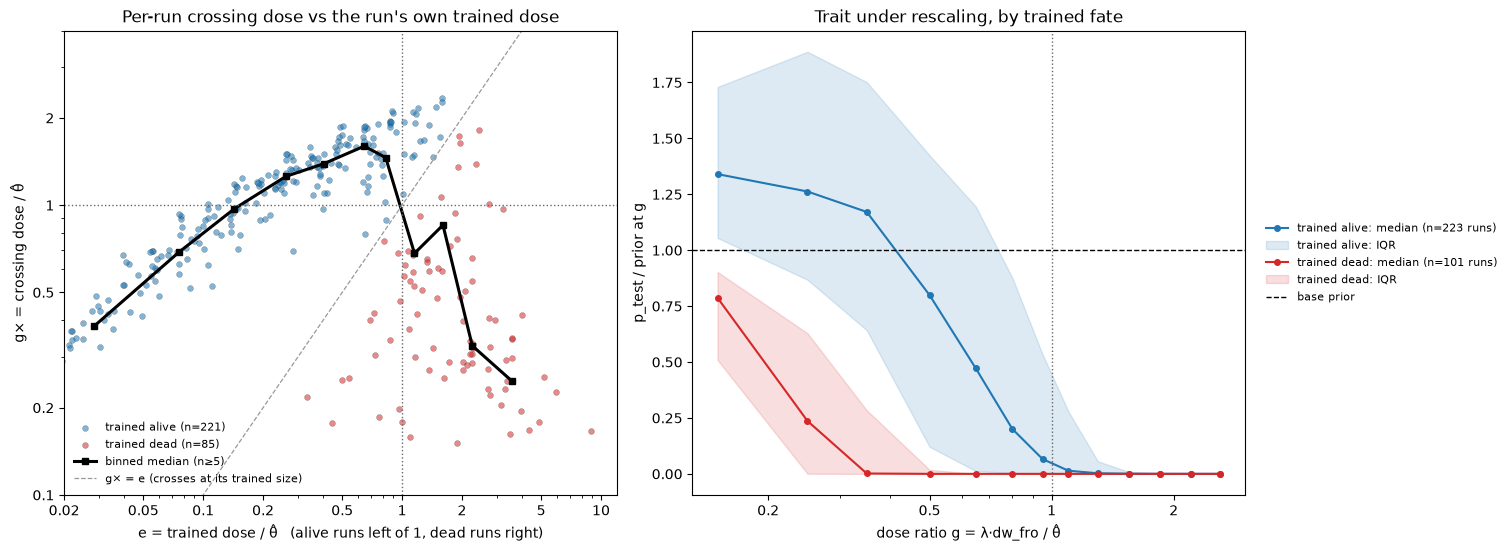

In [22]:
import statsmodels.api as sm
CENSUS = OUTPUT_ROOT / "analysis" / "dose_rescaling_census_qwen_20260910"
D = pd.read_csv(CENSUS / "results.csv")
D["g"] = D["dose_ratio"]; D["e"] = D["endpoint_dw_fro"] / D["theta"]
_rp = na.assign(rp=[str((dl.dataset_dir(OUTPUT_ROOT, NA_TEACHER, **KW) / t / "ftseed1").relative_to(OUTPUT_ROOT)) for t in na["tag"]]).set_index("rp")
D["trained_dead"] = D["run_path"].map(_rp["is_dead"]); D["p_x"] = D["p_target"] / p0
print(f"census points {len(D):,}; runs {D['run_path'].nunique()}; theta_hat (frozen) {D['theta'].iloc[0]:.4f}; nonfinite {int(D['nonfinite'].sum())}")
curve = D.groupby("g")["dead"].mean()
def g50(c):
    x = np.log(c.index.values); y = c.values - 0.5
    if (y > 0).any() and (y < 0).any():
        i = int(np.argmax(y > 0)); return float(np.exp(x[i-1] + (x[i]-x[i-1]) * (-y[i-1]) / (y[i]-y[i-1]))) if i > 0 else np.nan
    return np.nan
print(f"population 50% point: g50 = {g50(curve):.3f} (fraction dead at g=1: {curve.loc[curve.index[np.argmin(abs(curve.index-1.0))]]:.2f} at the nearest rung)")

def per_run(g_):
    g_ = g_.sort_values("g"); gs = g_["g"].values; dead = g_["dead"].values.astype(bool)
    y = g_["delta_ce"].values - g_["anchored_delta_ce_cut"].iloc[0]; x = np.log(gs); gc = np.nan
    if np.isfinite(y).all() and (y > 0).any() and (y < 0).any():
        i = int(np.argmax(y > 0))
        if i > 0: gc = float(np.exp(x[i-1] + (x[i]-x[i-1]) * (-y[i-1]) / (y[i]-y[i-1])))
    return pd.Series(dict(g_cross=gc, dead_at_min=bool(dead[0]), alive_at_max=bool(~dead[-1]),
                          nonmono=int(((~dead[1:]) & dead[:-1]).sum())))
Rn = D.groupby(["run_path", "rank", "e", "trained_dead"]).apply(per_run).reset_index()
Rn["lambda_star"] = Rn["g_cross"] / Rn["e"]
print(f"runs {len(Rn)}: crossing defined for {int(np.isfinite(Rn['g_cross']).sum())}; dead already at g=0.15: {int(Rn['dead_at_min'].sum())}; "
      f"alive at g=2.6: {int(Rn['alive_at_max'].sum())}; dead->alive reversals along a ladder: {int((Rn['nonmono'] > 0).sum())}")
rec = Rn[np.isfinite(Rn["g_cross"])]
print(f"fate reconstruction: (crossing below the trained endpoint) <=> (trained dead) agrees for {100*((rec['g_cross'] < rec['e']) == rec['trained_dead']).mean():.1f}% of {len(rec)} runs")
Rf = Rn[np.isfinite(Rn["g_cross"]) & (Rn["e"] > 0)].copy()
below = Rf[Rf["e"] < 0.7]; near = Rf[(Rf["e"] >= 0.7) & (Rf["e"] <= 1.4)]; above = Rf[Rf["e"] > 1.4]
def slope(x):
    if len(x) < 10: return (np.nan, np.nan, np.nan)
    m = sm.OLS(np.log(x["g_cross"]), sm.add_constant(np.log(x["e"]))).fit(); ci = m.conf_int().iloc[1]
    return (float(m.params.iloc[1]), float(ci.iloc[0]), float(ci.iloc[1]))
sb = slope(below); sa = slope(above)
tent = pd.Series({"runs with crossing": len(Rf), "median g× below (e<0.7)": round(below["g_cross"].median(), 3), "n below": len(below),
                  "median g× near (0.7-1.4)": round(near["g_cross"].median(), 3), "n near": len(near),
                  "median g× above (e>1.4)": round(above["g_cross"].median(), 3), "n above": len(above),
                  "slope below [95%]": f"{sb[0]:.2f} [{sb[1]:.2f}, {sb[2]:.2f}]", "slope above [95%]": f"{sa[0]:.2f} [{sa[1]:.2f}, {sa[2]:.2f}]",
                  "median lambda* near": round(near["lambda_star"].median(), 3)}, name="Qwen nonadaptive")
print("\nper-run crossing by where training ended (the tent; Pythia-160m strip for comparison: below 0.57, near 1.00, above 0.38, slopes +0.75 / -0.42):")
display(tent.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), constrained_layout=True)
ax = axes[0]
bins = [0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 3.0, 5.0, 10.0, np.inf]
Rf["ebin"] = pd.cut(Rf["e"], bins)
for dead_flag, col, lab in [(False, "tab:blue", "trained alive"), (True, "tab:red", "trained dead")]:
    s_ = Rf[Rf["trained_dead"] == dead_flag]; ax.scatter(s_["e"], s_["g_cross"], s=18, alpha=0.55, color=col, edgecolor="k", linewidth=0.2, label=f"{lab} (n={len(s_)})")
med = Rf.groupby("ebin", observed=True).agg(e=("e", "median"), gc=("g_cross", "median"), n=("g_cross", "size")); med = med[med["n"] >= 5]
ax.plot(med["e"], med["gc"], "k-", lw=2.2, marker="s", ms=5, label="binned median (n≥5)")
ax.axhline(1, color="0.4", ls=":", lw=1); ax.axvline(1, color="0.4", ls=":", lw=1); lo = np.array([1e-2, 30]); ax.plot(lo, lo, color="0.6", ls="--", lw=0.9, label="g× = e (crosses at its trained size)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.02, 12); ax.set_ylim(0.1, 4)
ax.set_xlabel("e = trained dose / θ̂   (alive runs left of 1, dead runs right)"); ax.set_ylabel("g× = crossing dose / θ̂")
ax.set_title("Per-run crossing dose vs the run's own trained dose"); ax.legend(fontsize=8, frameon=False, loc="lower left")
ax = axes[1]
for dead_flag, col, lab in [(False, "tab:blue", "trained alive"), (True, "tab:red", "trained dead")]:
    s_ = D[D["trained_dead"] == dead_flag].groupby("g")["p_x"]
    m, lo_, hi_ = s_.median(), s_.quantile(0.25), s_.quantile(0.75)
    ax.plot(m.index, m.values, "-o", ms=4, color=col, label=f"{lab}: median (n={D[D['trained_dead'] == dead_flag]['run_path'].nunique()} runs)")
    ax.fill_between(m.index, lo_.values, hi_.values, color=col, alpha=0.15, label=f"{lab}: IQR")
ax.axhline(1.0, color="k", ls="--", lw=1, label="base prior"); ax.axvline(1, color="0.4", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("dose ratio g = λ·dw_fro / θ̂"); ax.set_ylabel("p_test / prior at g"); ax.set_title("Trait under rescaling, by trained fate")
aplots.right_legend(ax, fontsize=8)
aplots.show()

### 8h. θ̂ and the dose map along training — every nonadaptive arm with checkpoint norms

At every saved checkpoint of every run, the realized dose (`eval/adapter_norms_traj.json`, the census
convention `dw_fro` = module-mean `(alpha/rank)·‖B·A‖_F/‖W0‖_F`) is joined with that checkpoint's own ΔCE
(`eval/pile_kl_traj.json`) through `analysis.norms.load_dose_trajectory_frame`. Per arm and per step:
θ̂(t) = the logistic 50 % crossing of that step's label on that step's dose (`theta_dose`), and the dose
map `dw_fro(t) ∝ lr^a·alpha^b·rank^c` (OLS on log dose). Arms = the nonadaptive designed sweeps that have
checkpoint norms today: Pythia-410m same-model (504 runs, 40 saves of 25,000 steps), OLMo-1B (432 runs,
41 saves of 12,500), Qwen (324 runs, 10 saves of 6,250). The Pythia-160m designed strip (504 × 2 seeds, 932 runs with 40 saves of 25,000 steps)
supplies its checkpoint doses from the older `ckpt_dose_trajectory` records (legacy flat files; same pooled
definition), read through the loader's fallback. Steps are
absolute; the table reads each arm at its first, quarter, half, three-quarter and last save.



Pythia-160m designed strip: cut 5.123, runs 464, saves 40; theta_hat 0.061 -> 0.153 (2.5x)


,n_dead,theta_hat,AUC,dose lr^a,alpha^b,rank^c
step,,,,,,
625,64,0.061,0.993,0.650,0.632,-0.404
6875,191,0.106,0.997,0.988,0.703,-0.280
13125,195,0.132,0.997,1.032,0.700,-0.257
19375,191,0.150,0.997,1.038,0.694,-0.251
25000,190,0.153,0.998,1.039,0.693,-0.251



Pythia-410m same-model: cut 5.474, runs 504, saves 40; theta_hat 0.051 -> 0.186 (3.6x)


,n_dead,theta_hat,AUC,dose lr^a,alpha^b,rank^c
step,,,,,,
625,108,0.051,0.988,0.725,0.702,-0.408
6875,183,0.133,0.995,1.010,0.738,-0.285
13125,176,0.177,0.997,1.039,0.720,-0.261
19375,171,0.195,0.996,1.037,0.710,-0.253
25000,175,0.186,0.995,1.037,0.708,-0.253



OLMo-1B: cut 5.186, runs 432, saves 20; theta_hat 0.090 -> 0.292 (3.2x)


,n_dead,theta_hat,AUC,dose lr^a,alpha^b,rank^c
step,,,,,,
625,163,0.090,0.995,1.194,0.686,-0.177
3750,209,0.199,0.994,1.283,0.695,-0.095
6875,210,0.257,0.994,1.273,0.672,-0.081
10000,205,0.286,0.995,1.266,0.663,-0.084
12500,203,0.292,0.995,1.265,0.661,-0.085



Qwen2.5-1.5B: cut 5.802, runs 324, saves 10; theta_hat 0.088 -> 0.160 (1.8x)


,n_dead,theta_hat,AUC,dose lr^a,alpha^b,rank^c
step,,,,,,
625,73,0.088,0.960,1.121,0.830,-0.352
1875,102,0.117,0.963,1.131,0.781,-0.288
3750,106,0.143,0.963,1.114,0.749,-0.255
5000,102,0.157,0.959,1.102,0.735,-0.247
6250,101,0.160,0.959,1.100,0.733,-0.246


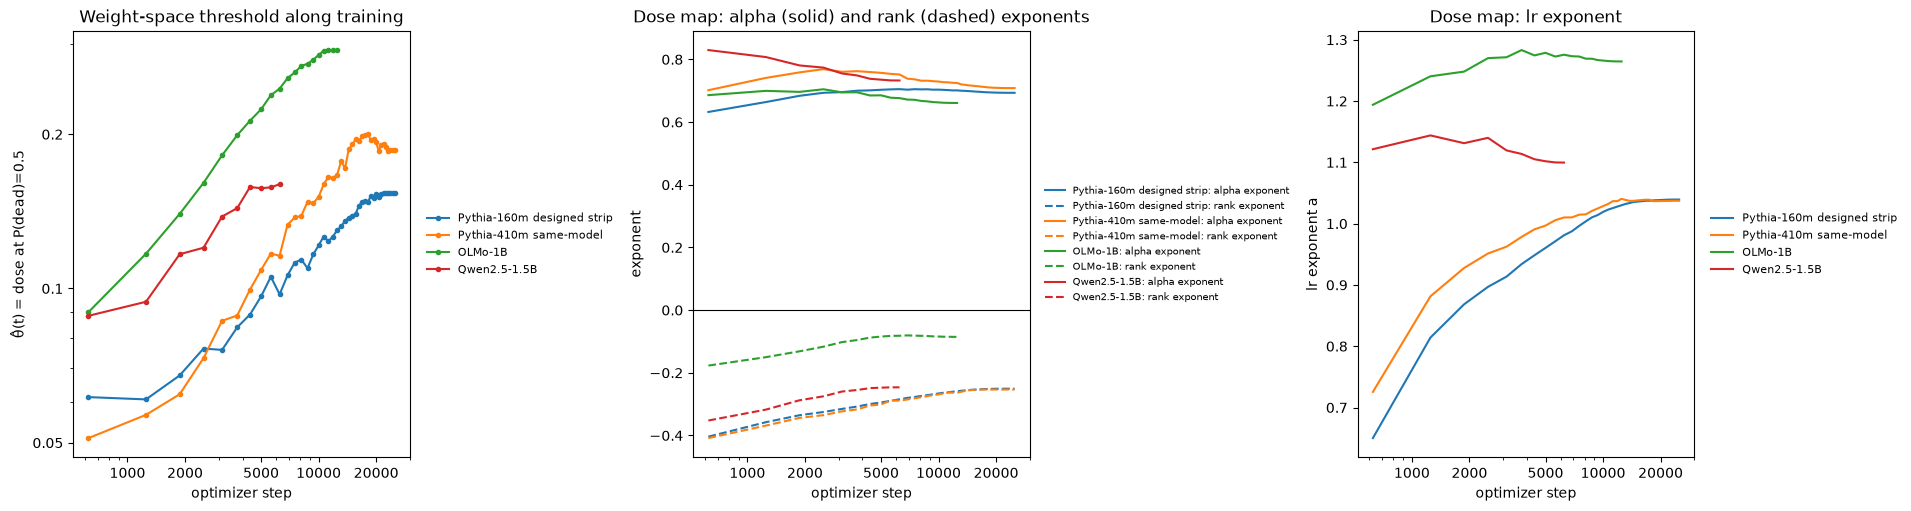

In [23]:
import re
from subliminal_learning.analysis.norms import load_dose_trajectory_frame
from subliminal_learning.weightspace.dose_census import ARM_SPECS, DD1B_ARM_SPECS, QWEN_ARM_SPECS
_specs = {s.name: s for s in ARM_SPECS + DD1B_ARM_SPECS + QWEN_ARM_SPECS}
TRAJ_ARMS = [("Pythia-160m designed strip", "strip", "EleutherAI/pythia-160m-data-seed1"),
             ("Pythia-410m same-model", "m410_same_model", "EleutherAI/pythia-410m"),
             ("OLMo-1B", "dd1b_same_model", None), ("Qwen2.5-1.5B", "qwen25_nonadaptive", None)]
_tagre = re.compile(r"ep\d+_lr([0-9e.-]+)_r(\d+)a(\d+)")
THETA_T = {}; DOSE_FRAMES = {}; CUTS = {}
for label, name, base in TRAJ_ARMS:
    s = _specs[name]; root = OUTPUT_ROOT / s.rel_root
    if s.inventory_file:   # the strip arm is the DESIGNED 504 x 2 population, listed explicitly
        runs = [ln.strip() for ln in (Path("..") / s.inventory_file).read_text().splitlines() if ln.strip()]
    else:
        runs = [str(q.relative_to(OUTPUT_ROOT)) for q in sorted(root.glob(s.glob)) if q.is_dir()]
    cut = labels.anchored_cut(OUTPUT_ROOT, base or s.anchor_base, pool=s.pool); CUTS[label] = cut
    L = load_dose_trajectory_frame(OUTPUT_ROOT, runs, dead_cut=cut)
    L["tag"] = L["run_path"].str.split("/").str[-2]; L["lr"] = L["tag"].map(lambda t: float(_tagre.search(t)[1])); L["student_tag"] = L["tag"]
    # OLMo mixes a 312- and a 625-step save cadence (624, 1248, ... sit 0.16% off the 625 grid): snap every
    # save to the nearest multiple of 625 when within 1%, drop the off-grid ones, then keep only steps seen
    # by >= 90% of the runs so theta(t) is always fit on the same population.
    grid = 625.0 * np.round(L["step"] / 625.0); L = L[np.abs(L["step"] - grid) <= 0.01 * L["step"]].copy(); L["step"] = grid[L.index].astype(int)
    L = L.drop_duplicates(["run_path", "step"], keep="last")
    n_runs = L["run_path"].nunique(); counts = L.groupby("step")["run_path"].nunique(); L = L[L["step"].isin(counts[counts >= 0.9 * n_runs].index)]
    DOSE_FRAMES[label] = L
    rows = []
    for st, g in L.groupby("step"):
        if g["collapsed"].nunique() < 2 or g["collapsed"].sum() < 5: continue
        th = cl.theta_dose(g, "dw_fro")
        X = sm.add_constant(np.column_stack([np.log(g["lr"]), np.log(g["alpha"].astype(float)), np.log(g["rank"].astype(float))]))
        pm = np.asarray(sm.OLS(np.log(g["dw_fro"]), X).fit().params)
        rows.append(dict(step=int(st), n_dead=int(g["collapsed"].sum()), theta_hat=th["theta"], AUC=th["auc"], **{"dose lr^a": pm[1], "alpha^b": pm[2], "rank^c": pm[3]}))
    THETA_T[label] = pd.DataFrame(rows).set_index("step")
    steps = list(THETA_T[label].index); pick = [steps[0], steps[len(steps)//4], steps[len(steps)//2], steps[3*len(steps)//4], steps[-1]]
    print(f"\n{label}: cut {cut:.3f}, runs {L['run_path'].nunique()}, saves {len(steps)}; theta_hat {THETA_T[label]['theta_hat'].iloc[0]:.3f} -> {THETA_T[label]['theta_hat'].iloc[-1]:.3f} ({THETA_T[label]['theta_hat'].iloc[-1]/THETA_T[label]['theta_hat'].iloc[0]:.1f}x)")
    display(THETA_T[label].loc[pick].round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
pal_arm = aplots.palette([a[0] for a in TRAJ_ARMS], cmap="tab10")
for label, _, _ in TRAJ_ARMS:
    T = THETA_T[label]
    axes[0].plot(T.index, T["theta_hat"], "-o", ms=3, color=pal_arm[label], label=label)
    axes[1].plot(T.index, T["alpha^b"], "-", color=pal_arm[label], label=f"{label}: alpha exponent")
    axes[1].plot(T.index, T["rank^c"], "--", color=pal_arm[label], label=f"{label}: rank exponent")
    axes[2].plot(T.index, T["dose lr^a"], "-", color=pal_arm[label], label=label)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("optimizer step"); axes[0].set_ylabel("θ̂(t) = dose at P(dead)=0.5"); axes[0].set_title("Weight-space threshold along training")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xscale("log"); axes[1].set_xlabel("optimizer step"); axes[1].set_ylabel("exponent"); axes[1].set_title("Dose map: alpha (solid) and rank (dashed) exponents")
axes[2].set_xscale("log"); axes[2].set_xlabel("optimizer step"); axes[2].set_ylabel("lr exponent a"); axes[2].set_title("Dose map: lr exponent")
aplots.right_legend(axes[0], fontsize=8); aplots.right_legend(axes[1], fontsize=7); aplots.right_legend(axes[2], fontsize=8)
aplots.show()

### 8i. When a run dies, is its dose at that moment θ̂ of that moment? (cross-fitted)

The training-time version of the census question, with no rescaling. Row unit: one trained-dead run.
`t_death` is the first saved step at which its own ΔCE exceeds the cut; `d×` is its dose at the crossing,
log-linearly interpolated between the previous save and `t_death` (a run already dead at its first save has
no interpolable crossing and is counted separately — censored from above). The ratio `d×/θ̂(t_death)`
compares that dose with the population threshold **at the same step**; `d×/θ̂(end)` with the endpoint
threshold, i.e. what a single fitted θ would use.

**Cross-fitting.** A run's own death is part of the population that θ̂(t) is fitted on, so scoring it
against that θ̂ is partly circular. Here the runs are split into two halves by a stable hash; θ̂(t) and
θ̂(end) are fitted on one half and every death in the *other* half is scored against them, then the
halves are swapped and pooled. The in-sample version is shown beside it for reference.


dead runs per arm and how many were already dead at the first save (censored; excluded below):


,dead_runs,dead_at_first_save,median_t_death
arm,,,
OLMo-1B,203,163,625.0
Pythia-160m designed strip,190,64,1250.0
Pythia-410m same-model,217,108,1250.0
Qwen2.5-1.5B,101,72,625.0



crossing dose over the threshold of the same step vs over the endpoint threshold (row unit: one (arm, scheme); quartiles over interpolated crossings):


n  d×/θ̂(t) q25  d×/θ̂(t) median  d×/θ̂(t) q75  d×/θ̂(end) q25  d×/θ̂(end) median  d×/θ̂(end) q75
arm                        scheme                                                                                                        
OLMo-1B                    cross-fit   40         0.752            0.892         1.017           0.297              0.369           0.523
                           in-sample   40         0.738            0.908         1.040           0.295              0.379           0.512
Pythia-160m designed strip cross-fit  126         0.630            0.814         1.248           0.267              0.353           0.544
                           in-sample  126         0.638            0.827         1.250           0.267              0.359           0.554
Pythia-410m same-model     cross-fit  109         0.595            0.791         1.151           0.188              0.273           0.412
                           in-sample  109         0.585            0.776         1.179           0.190              0.282           0.398
Qwen2.5-1.5B               cross-fit   29         0.698            0.958         1.426           0.456              0.553           0.865
                           in-sample   29         0.715            0.935         1.390           0.455              0.552           0.862


paired: is each cross-fit death closer (in log distance) to the same-step threshold or to the endpoint one?


,n,median |log10 d×/θ̂(t)|,median |log10 d×/θ̂(end)|,frac closer to θ̂(t)
arm,,,,
OLMo-1B,40,0.095,0.432,0.975
Pythia-160m designed strip,126,0.157,0.452,0.905
Pythia-410m same-model,109,0.183,0.563,0.927
Qwen2.5-1.5B,29,0.156,0.257,0.690


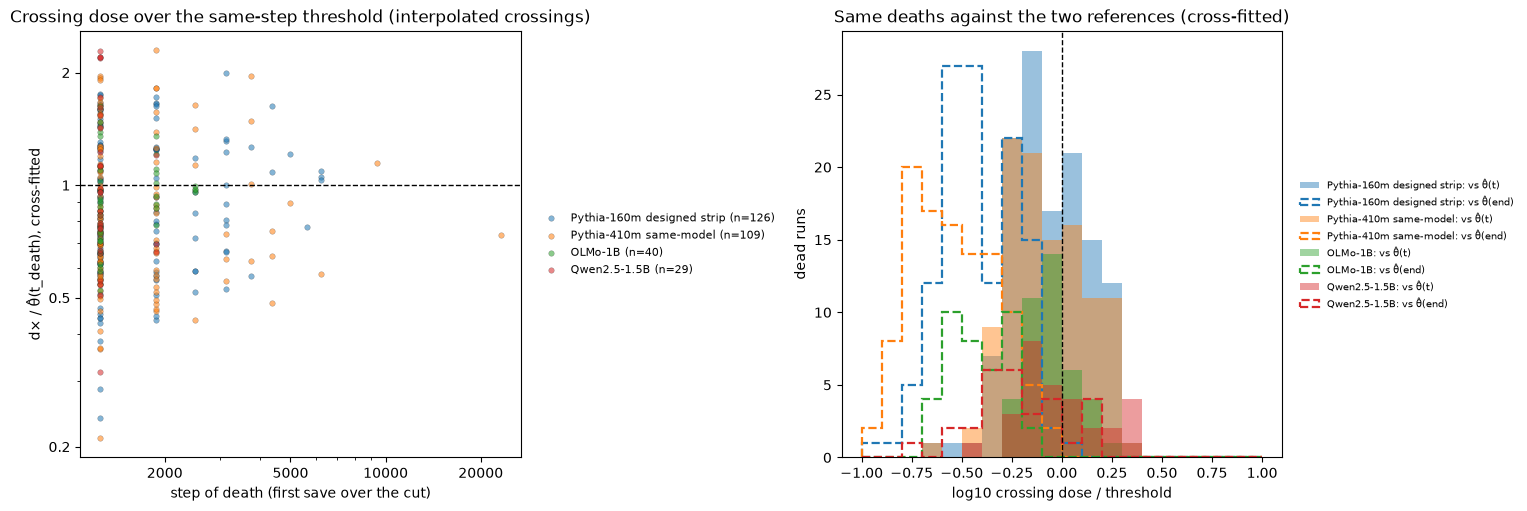

In [24]:
import hashlib
def _half(rp): return int(hashlib.sha1(rp.encode()).hexdigest(), 16) % 2

def theta_curve(L):
    """theta_hat per step (population-complete steps only), for a sub-population."""
    out = {}
    for st, g in L.groupby("step"):
        if g["collapsed"].nunique() < 2 or g["collapsed"].sum() < 5: continue
        out[int(st)] = cl.theta_dose(g, "dw_fro")["theta"]
    return pd.Series(out).sort_index()

def deaths(L, theta_t, cut, label, scheme):
    rows = []
    for rp, g in L.groupby("run_path"):
        g = g.sort_values("step").reset_index(drop=True)
        if g["collapsed"].iloc[-1] == 0 or g["collapsed"].sum() == 0: continue
        i = int(np.argmax(g["collapsed"].values == 1)); td = int(g["step"].iloc[i])
        if td not in theta_t.index: continue
        if i == 0:
            dx, kind = float(g["dw_fro"].iloc[0]), "dead at first save"
        else:
            y0, y1 = g["delta_ce"].iloc[i-1] - cut, g["delta_ce"].iloc[i] - cut; x0, x1 = np.log(g["dw_fro"].iloc[i-1]), np.log(g["dw_fro"].iloc[i])
            dx, kind = (float(np.exp(x0 + (x1 - x0) * (-y0) / (y1 - y0))) if y1 != y0 else float(g["dw_fro"].iloc[i])), "interpolated"
        rows.append(dict(arm=label, scheme=scheme, run_path=rp, t_death=td, d_cross=dx, theta_at_t=theta_t.loc[td], theta_end=theta_t.iloc[-1], kind=kind))
    return rows

death = []
for label, _, _ in TRAJ_ARMS:
    L = DOSE_FRAMES[label]; cut = CUTS[label]
    death += deaths(L, THETA_T[label]["theta_hat"], cut, label, "in-sample")
    halves = L["run_path"].map(_half)
    for h in (0, 1):
        th = theta_curve(L[halves != h])              # fit on the other half
        death += deaths(L[halves == h], th, cut, label, "cross-fit")
DT = pd.DataFrame(death); DT["ratio_t"] = DT["d_cross"] / DT["theta_at_t"]; DT["ratio_end"] = DT["d_cross"] / DT["theta_end"]
q = lambda p: (lambda s: s.quantile(p))
interp = DT[DT["kind"] == "interpolated"]
tab = interp.groupby(["arm", "scheme"]).agg(n=("run_path", "size"), **{"d×/θ̂(t) q25": ("ratio_t", q(.25)), "d×/θ̂(t) median": ("ratio_t", "median"), "d×/θ̂(t) q75": ("ratio_t", q(.75)),
                                             "d×/θ̂(end) q25": ("ratio_end", q(.25)), "d×/θ̂(end) median": ("ratio_end", "median"), "d×/θ̂(end) q75": ("ratio_end", q(.75))})
cens = DT[DT["scheme"] == "in-sample"].groupby("arm").agg(dead_runs=("run_path", "size"), dead_at_first_save=("kind", lambda s: int((s == "dead at first save").sum())), median_t_death=("t_death", "median"))
print("dead runs per arm and how many were already dead at the first save (censored; excluded below):"); display(cens)
print("\ncrossing dose over the threshold of the same step vs over the endpoint threshold (row unit: one (arm, scheme); quartiles over interpolated crossings):")
display(tab.round(3))
# a paired view: for each cross-fit death, |log ratio| under the two references
cf = interp[interp["scheme"] == "cross-fit"].copy(); cf["abs_log_t"] = np.abs(np.log10(cf["ratio_t"])); cf["abs_log_end"] = np.abs(np.log10(cf["ratio_end"]))
paired = cf.groupby("arm").agg(n=("run_path", "size"), **{"median |log10 d×/θ̂(t)|": ("abs_log_t", "median"), "median |log10 d×/θ̂(end)|": ("abs_log_end", "median"),
                               "frac closer to θ̂(t)": ("abs_log_t", lambda s: float((s < cf.loc[s.index, "abs_log_end"]).mean()))})
print("\npaired: is each cross-fit death closer (in log distance) to the same-step threshold or to the endpoint one?"); display(paired.round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax = axes[0]
for label, _, _ in TRAJ_ARMS:
    s_ = cf[cf["arm"] == label]
    ax.scatter(s_["t_death"], s_["ratio_t"], s=16, alpha=0.55, color=pal_arm[label], edgecolor="k", linewidth=0.2, label=f"{label} (n={len(s_)})")
ax.axhline(1, color="k", ls="--", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("step of death (first save over the cut)"); ax.set_ylabel("d× / θ̂(t_death), cross-fitted")
ax.set_title("Crossing dose over the same-step threshold (interpolated crossings)"); aplots.right_legend(ax, fontsize=8)
ax = axes[1]
bins_ = np.linspace(-1, 1, 21)
for label, _, _ in TRAJ_ARMS:
    s_ = cf[cf["arm"] == label]
    ax.hist(np.log10(s_["ratio_t"]), bins=bins_, alpha=0.45, color=pal_arm[label], label=f"{label}: vs θ̂(t)")
    ax.hist(np.log10(s_["ratio_end"]), bins=bins_, histtype="step", lw=1.6, color=pal_arm[label], ls="--", label=f"{label}: vs θ̂(end)")
ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel("log10 crossing dose / threshold"); ax.set_ylabel("dead runs"); ax.set_title("Same deaths against the two references (cross-fitted)"); aplots.right_legend(ax, fontsize=7)
aplots.show()

### 8j. Does the eval-time crossing dose of a dead adapter match θ̂ at the step it died?

Angela's question (09-10). The census (§8g) rescales each run's **final** adapter and finds the absolute dose
`D× = g×·θ̂_frozen` at which it kills. §8h gives θ̂(t), the population tolerance at every save. For each
trained-dead run, `t_death` is its first save over the cut (§8i). The comparison is `D× / θ̂(t_death)` against
`D× / θ̂(end)`: if a dead adapter's lethality was fixed at the time it died (its direction stopped changing
once the model collapsed), the rescaled final adapter should kill at roughly the tolerance *of that time*,
not the endpoint tolerance the census normalised by — which would explain why the tent's right side sits
well below 1. Row unit of the table: one arm (quartiles over its dead runs with a census crossing);
the per-step view lists the median ratio by death step. Runs dead at the first save are censored (their true
death step, and the tolerance then, are earlier/lower than the first save), so ratios below 1 there are
expected. Arms: every nonadaptive arm with both a census and checkpoint doses.


census crossing dose of the FINAL adapter against θ̂ at the run's own death step (row unit: one arm):


arm,Pythia-160m designed strip,Pythia-410m same-model,OLMo-1B,Qwen2.5-1.5B
dead runs with a census crossing,187.000,60.000,37.000,85.000
of which dead at first save,62.000,0.000,10.000,56.000
θ̂ first save,0.061,0.051,0.090,0.088
θ̂ end,0.153,0.186,0.292,0.160
D×/θ̂(t_death) q25,0.768,1.336,0.488,0.460
D×/θ̂(t_death) median,0.960,1.770,0.637,0.623
D×/θ̂(t_death) q75,1.600,2.435,1.127,1.032
D×/θ̂(end) median,0.394,0.700,0.242,0.348
"Spearman(D×, t_death)",0.791,0.414,0.652,0.507



Pythia-160m designed strip: median ratio by death step (row unit: one death step):


,n,D×/θ̂(t),D×/θ̂(end),θ̂(t)
t_death,,,,
625,62,0.712,0.294,0.061
1250,73,0.970,0.396,0.061
1875,25,1.775,0.807,0.068
2500,7,1.498,0.768,0.076
3125,11,1.578,0.804,0.076
3750,2,1.870,1.055,0.084
4375,2,2.068,1.236,0.089
5000,1,1.952,1.265,0.096



Pythia-410m same-model: median ratio by death step (row unit: one death step):


,n,D×/θ̂(t),D×/θ̂(end),θ̂(t)
t_death,,,,
1250,16,1.683,0.512,0.057
1875,26,2.108,0.703,0.062
2500,4,2.555,1.003,0.073
3125,3,1.550,0.719,0.086
3750,4,2.097,0.997,0.089
4375,3,1.238,0.661,0.100
5000,1,1.302,0.759,0.109
6250,1,1.125,0.699,0.116



OLMo-1B: median ratio by death step (row unit: one death step):


,n,D×/θ̂(t),D×/θ̂(end),θ̂(t)
t_death,,,,
625,10,0.577,0.183,0.090
1250,16,0.458,0.189,0.117
1875,7,0.859,0.424,0.140
2500,4,1.492,0.848,0.161



Qwen2.5-1.5B: median ratio by death step (row unit: one death step):


,n,D×/θ̂(t),D×/θ̂(end),θ̂(t)
t_death,,,,
625,56,0.544,0.301,0.088
1250,26,1.056,0.622,0.094
1875,3,0.953,0.696,0.117


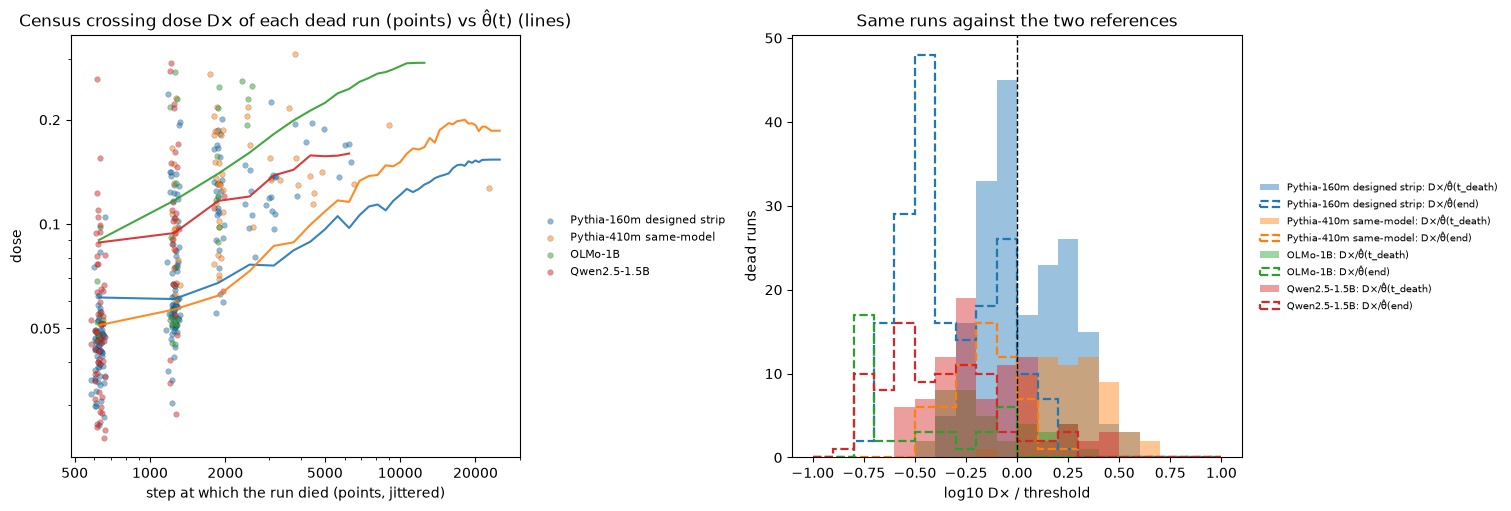

In [25]:
from scipy.stats import spearmanr
CENSUS_CSV = {"Pythia-160m designed strip": ("strip", "analysis/dose_rescaling_census_20260902/results.csv"),
              "Pythia-410m same-model": ("m410_same_model", "analysis/dose_rescaling_census_20260902/results.csv"),
              "OLMo-1B": ("dd1b_same_model", "analysis/dose_rescaling_census_dd1b_20260904/results.csv"),
              "Qwen2.5-1.5B": ("qwen25_nonadaptive", "analysis/dose_rescaling_census_qwen_20260910/results.csv")}
def _gx(g_):
    g_ = g_.sort_values("dose_ratio"); y = g_["delta_ce"].values - g_["anchored_delta_ce_cut"].iloc[0]; x = np.log(g_["dose_ratio"].values)
    if np.isfinite(y).all() and (y > 0).any() and (y < 0).any():
        i = int(np.argmax(y > 0))
        if i > 0: return float(np.exp(x[i-1] + (x[i]-x[i-1]) * (-y[i-1]) / (y[i]-y[i-1])))
    return np.nan
JX = {}; rows_j = []
for label, _, _ in TRAJ_ARMS:
    arm_name, csv = CENSUS_CSV[label]; C = pd.read_csv(OUTPUT_ROOT / csv); C = C[C["arm"] == arm_name]
    cen = C.groupby("run_path").apply(lambda g: pd.Series(dict(g_cross=_gx(g), theta_frozen=g["theta"].iloc[0]))).reset_index()
    cen["D_cross"] = cen["g_cross"] * cen["theta_frozen"]
    L = DOSE_FRAMES[label]; th = THETA_T[label]["theta_hat"]; cut = CUTS[label]
    rec = []
    for rp, g in L.groupby("run_path"):
        g = g.sort_values("step").reset_index(drop=True)
        if g["collapsed"].iloc[-1] == 0 or g["collapsed"].sum() == 0: continue
        i = int(np.argmax(g["collapsed"].values == 1)); td = int(g["step"].iloc[i])
        if td in th.index: rec.append(dict(run_path=rp, t_death=td, first_save=(i == 0), theta_t=th.loc[td], dose_at_death=float(g["dw_fro"].iloc[i])))
    J = pd.DataFrame(rec).merge(cen, on="run_path"); J = J[np.isfinite(J["D_cross"])].copy()
    J["r_t"] = J["D_cross"] / J["theta_t"]; J["r_end"] = J["D_cross"] / J["theta_frozen"]; JX[label] = J
    rows_j.append({"arm": label, "dead runs with a census crossing": len(J), "of which dead at first save": int(J["first_save"].sum()),
                   "θ̂ first save": float(th.iloc[0]), "θ̂ end": float(th.iloc[-1]),
                   "D×/θ̂(t_death) q25": J["r_t"].quantile(.25), "D×/θ̂(t_death) median": J["r_t"].median(), "D×/θ̂(t_death) q75": J["r_t"].quantile(.75),
                   "D×/θ̂(end) median": J["r_end"].median(), "Spearman(D×, t_death)": spearmanr(J["t_death"], J["D_cross"])[0]})
print("census crossing dose of the FINAL adapter against θ̂ at the run's own death step (row unit: one arm):")
display(pd.DataFrame(rows_j).set_index("arm").round(3).T)
for label, J in JX.items():
    print(f"\n{label}: median ratio by death step (row unit: one death step):")
    display(J.groupby("t_death").agg(n=("run_path", "size"), **{"D×/θ̂(t)": ("r_t", "median"), "D×/θ̂(end)": ("r_end", "median"), "θ̂(t)": ("theta_t", "first")}).head(8).round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax = axes[0]
for label, J in JX.items():
    ax.scatter(J["t_death"] * (1 + 0.03 * np.random.default_rng(0).standard_normal(len(J))), J["D_cross"], s=16, alpha=0.5, color=pal_arm[label], edgecolor="k", linewidth=0.2, label=label)
    T = THETA_T[label]["theta_hat"]; ax.plot(T.index, T.values, "-", color=pal_arm[label], lw=1.5, alpha=0.9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("step at which the run died (points, jittered)"); ax.set_ylabel("dose")
ax.set_title("Census crossing dose D× of each dead run (points) vs θ̂(t) (lines)"); aplots.right_legend(ax, fontsize=8)
ax = axes[1]
bins_ = np.linspace(-1, 1, 21)
for label, J in JX.items():
    ax.hist(np.log10(J["r_t"]), bins=bins_, alpha=0.45, color=pal_arm[label], label=f"{label}: D×/θ̂(t_death)")
    ax.hist(np.log10(J["r_end"]), bins=bins_, histtype="step", lw=1.6, ls="--", color=pal_arm[label], label=f"{label}: D×/θ̂(end)")
ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel("log10 D× / threshold"); ax.set_ylabel("dead runs"); ax.set_title("Same runs against the two references"); aplots.right_legend(ax, fontsize=7)
aplots.show()

### 8k. Resolving the death step: the early-stopped strip (`_stop1250`, 16 saves in the first 1,250 steps)

The 504 seed-1 cells of the Pythia-160m designed strip retrained with the FULL 25,000-step schedule but stopped
after step 1,250 (end of warm-up), saving at 25, 50, 75, 100, 150, 200, 250, 300, 400, 500, 625, 750, 875, 1000,
1125, 1250 (`TrainConfig.stop_step`/`save_at_steps`, `students.early_stop`; worker
`run_logs/strip_earlystop_worker.py`; the first 1,250 steps retrace the original run). Per save: pile-KL ΔCE,
trait, and dose. This resolves (i) θ̂(t) inside the warm-up and (ii) each early death's step to 25–125 steps,
so the census crossing dose D× of the ORIGINAL run's final adapter (§8g census, seed 1) can be compared with
the tolerance and with the run's own dose at the moment it died. Row units: one save step (θ̂ table); one
dead run (ratios). Runs whose death lies past 1,250 are not in this arm.


early-stop arm: 502 runs, saves [np.int64(25), np.int64(50), np.int64(75), np.int64(100), np.int64(150), np.int64(200), np.int64(250), np.int64(300), np.int64(400), np.int64(500), np.int64(625), np.int64(750), np.int64(875), np.int64(1000), np.int64(1125), np.int64(1250)]
theta_hat inside the warm-up (row unit: one save step; label and dose both at that step):


,25,50,75,100,150,200,250,300,400,500,625,750,875,1000,1125,1250
runs over the cut,0.0000,0.0000,0.000,3.0000,12.0000,26.0000,39.0000,44.0000,68.0000,91.0000,104.0000,122.0000,140.0000,152.0000,169.0000,176.0000
theta_hat(t),NaN,NaN,NaN,NaN,0.0885,0.0640,0.0610,0.0692,0.0593,0.0532,0.0605,0.0610,0.0590,0.0611,0.0572,0.0613
median dose alive,0.0001,0.0005,0.001,0.0015,0.0022,0.0026,0.0030,0.0035,0.0040,0.0044,0.0051,0.0053,0.0057,0.0058,0.0062,0.0066
median dose dead,NaN,NaN,NaN,0.1177,0.0994,0.1213,0.1112,0.1246,0.1354,0.1299,0.1613,0.1684,0.1831,0.1959,0.1925,0.2143



runs over the cut within 1,250 steps: 178 of 502; dead at the first save (25): 0; transiently over the cut but alive at 1,250: 2
death-step counts: {100: 3, 150: 9, 200: 14, 250: 13, 300: 7, 400: 22, 500: 24, 625: 13, 750: 17, 875: 18, 1000: 13, 1125: 17, 1250: 8}

census crossing dose of the ORIGINAL run's final adapter vs three references (row unit: one reference; quartiles over dead runs with a census crossing):


,q25,median,q75,n
D×/θ̂(t_death),0.754,0.890,1.172,135
D×/θ̂(end),0.294,0.355,0.445,135
D×/own dose at death,0.719,1.048,1.539,135



by resolved death step (row unit: one death step):


,n,D×/θ̂(t),D×/own dose,θ̂(t),median own dose at death,median D×
t_death,,,,,,
200,1,0.896,0.500,0.064,0.115,0.057
250,2,0.636,0.989,0.061,0.056,0.039
300,4,0.522,0.622,0.069,0.072,0.036
400,20,0.725,0.624,0.059,0.066,0.043
500,23,0.838,0.950,0.053,0.046,0.045
625,13,0.802,0.987,0.060,0.048,0.048
750,16,0.897,1.111,0.061,0.045,0.055
875,18,0.949,1.143,0.059,0.058,0.056
1000,13,1.056,1.471,0.061,0.049,0.064


Spearman(D×, t_death) = 0.73;  Spearman(D×, own dose at death) = 0.08;  Spearman(own dose at death, t_death) = -0.03


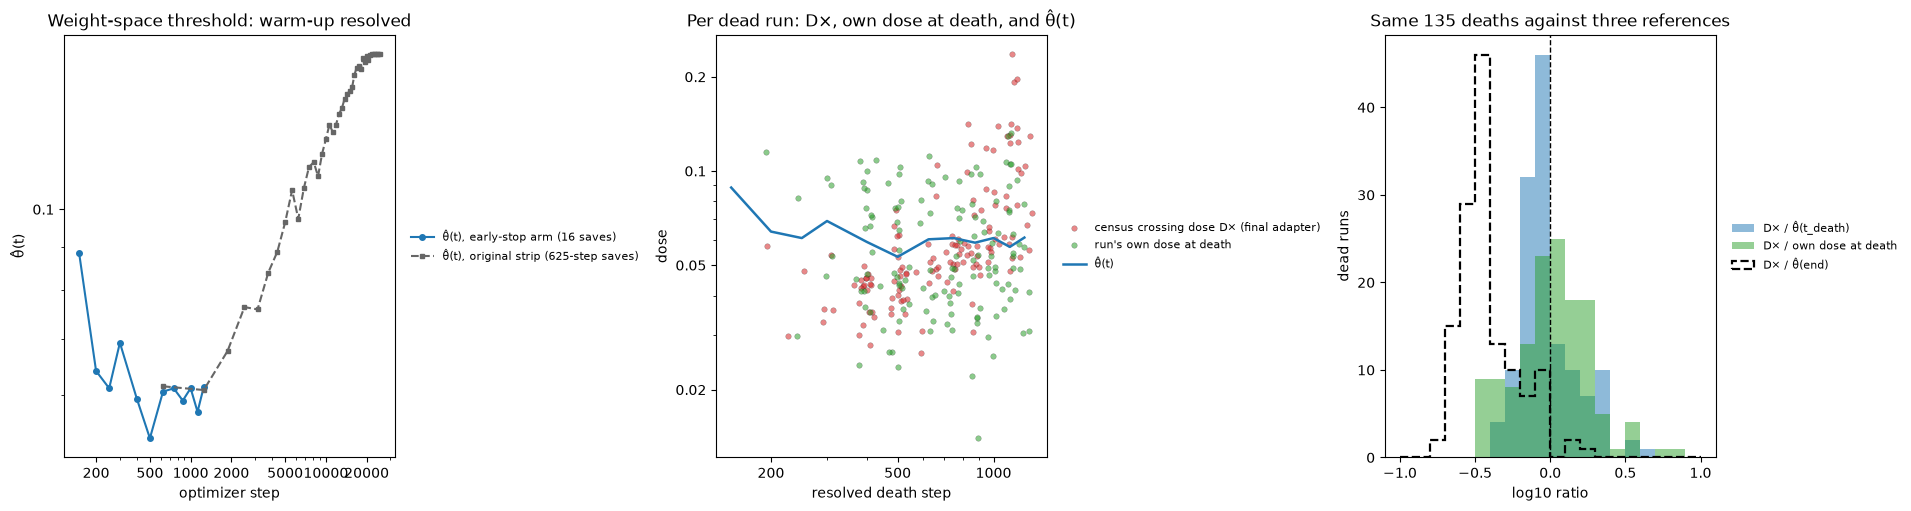

In [26]:

ES_LIN = OUTPUT_ROOT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k"
es_runs = [str(q.relative_to(OUTPUT_ROOT)) for q in sorted(ES_LIN.glob("ep20_*_stop1250/ftseed1")) if (q / "eval" / "pile_kl_traj.json").exists()]
ES_CUT = labels.anchored_cut(OUTPUT_ROOT, "EleutherAI/pythia-160m-data-seed1", pool="pp1")
E = load_dose_trajectory_frame(OUTPUT_ROOT, es_runs, dead_cut=ES_CUT)
E["tag"] = E["run_path"].str.split("/").str[-2]; E["orig_tag"] = E["tag"].str.replace("_stop1250", "", regex=False); E["student_tag"] = E["tag"]
E["lr"] = E["tag"].map(lambda t: float(_tagre.search(t)[1]))
th_es = pd.Series({int(st): cl.theta_dose(g, "dw_fro")["theta"] for st, g in E.groupby("step") if g["collapsed"].nunique() == 2 and g["collapsed"].sum() >= 5}).sort_index()
tab_es = pd.DataFrame({"runs over the cut": E.groupby("step")["collapsed"].sum().astype(int), "theta_hat(t)": th_es,
                       "median dose alive": E[E["collapsed"] == 0].groupby("step")["dw_fro"].median(), "median dose dead": E[E["collapsed"] == 1].groupby("step")["dw_fro"].median()})
print(f"early-stop arm: {E['run_path'].nunique()} runs, saves {sorted(E['step'].unique())}")
print("theta_hat inside the warm-up (row unit: one save step; label and dose both at that step):"); display(tab_es.round(4).T)

C = pd.read_csv(OUTPUT_ROOT / "analysis/dose_rescaling_census_20260902/results.csv"); C = C[(C["arm"] == "strip") & C["run_path"].str.endswith("ftseed1")]
cen = C.groupby("run_path").apply(lambda g: pd.Series(dict(g_cross=_gx(g), theta_frozen=g["theta"].iloc[0], e=g["endpoint_dw_fro"].iloc[0] / g["theta"].iloc[0]))).reset_index()
cen["D_cross"] = cen["g_cross"] * cen["theta_frozen"]; cen["orig_tag"] = cen["run_path"].str.split("/").str[-2]
rows_e = []
for rp, g in E.groupby("run_path"):
    g = g.sort_values("step").reset_index(drop=True)
    if g["collapsed"].sum() == 0: continue
    i = int(np.argmax(g["collapsed"].values == 1)); td = int(g["step"].iloc[i])
    if i == 0:
        dx, kind = float(g["dw_fro"].iloc[0]), "dead at first save"
    else:
        y0, y1 = g["delta_ce"].iloc[i-1] - ES_CUT, g["delta_ce"].iloc[i] - ES_CUT; x0, x1 = np.log(g["dw_fro"].iloc[i-1]), np.log(g["dw_fro"].iloc[i])
        dx, kind = (float(np.exp(x0 + (x1 - x0) * (-y0) / (y1 - y0))) if y1 != y0 else float(g["dw_fro"].iloc[i])), "interpolated"
    rows_e.append(dict(orig_tag=g["orig_tag"].iloc[0], t_death=td, kind=kind, dose_at_death=dx, theta_t=th_es.get(td, np.nan), alive_at_1250=bool(g["collapsed"].iloc[-1] == 0)))
DE = pd.DataFrame(rows_e).merge(cen[["orig_tag", "D_cross", "e", "theta_frozen"]], on="orig_tag", how="left")
print(f"\nruns over the cut within 1,250 steps: {len(DE)} of {E['run_path'].nunique()}; dead at the first save (25): {int((DE['kind'] != 'interpolated').sum())}; "
      f"transiently over the cut but alive at 1,250: {int(DE['alive_at_1250'].sum())}")
print("death-step counts:", DE["t_death"].value_counts().sort_index().to_dict())
DV = DE[np.isfinite(DE["D_cross"]) & np.isfinite(DE["theta_t"])].copy()
DV["D×/θ̂(t_death)"] = DV["D_cross"] / DV["theta_t"]; DV["D×/θ̂(end)"] = DV["D_cross"] / DV["theta_frozen"]; DV["D×/own dose at death"] = DV["D_cross"] / DV["dose_at_death"]
summ = DV[["D×/θ̂(t_death)", "D×/θ̂(end)", "D×/own dose at death"]].quantile([.25, .5, .75]).T; summ.columns = ["q25", "median", "q75"]; summ["n"] = len(DV)
print("\ncensus crossing dose of the ORIGINAL run's final adapter vs three references (row unit: one reference; quartiles over dead runs with a census crossing):"); display(summ.round(3))
bystep = DV.groupby("t_death").agg(n=("D_cross", "size"), **{"D×/θ̂(t)": ("D×/θ̂(t_death)", "median"), "D×/own dose": ("D×/own dose at death", "median"), "θ̂(t)": ("theta_t", "first"), "median own dose at death": ("dose_at_death", "median"), "median D×": ("D_cross", "median")})
print("\nby resolved death step (row unit: one death step):"); display(bystep.round(3))
print(f"Spearman(D×, t_death) = {spearmanr(DV['t_death'], DV['D_cross'])[0]:.2f};  Spearman(D×, own dose at death) = {spearmanr(DV['dose_at_death'], DV['D_cross'])[0]:.2f};  "
      f"Spearman(own dose at death, t_death) = {spearmanr(DV['dose_at_death'], DV['t_death'])[0]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
ax = axes[0]; ax.plot(th_es.index, th_es.values, "-o", ms=4, color="tab:blue", label="θ̂(t), early-stop arm (16 saves)")
T160 = THETA_T["Pythia-160m designed strip"]["theta_hat"]; ax.plot(T160.index, T160.values, "--s", ms=3, color="0.4", label="θ̂(t), original strip (625-step saves)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("optimizer step"); ax.set_ylabel("θ̂(t)"); ax.set_title("Weight-space threshold: warm-up resolved"); aplots.right_legend(ax, fontsize=8)
ax = axes[1]
ax.scatter(DV["t_death"] * (1 + 0.04 * np.random.default_rng(0).standard_normal(len(DV))), DV["D_cross"], s=16, alpha=0.55, color="tab:red", edgecolor="k", linewidth=0.2, label="census crossing dose D× (final adapter)")
ax.scatter(DV["t_death"] * (1 + 0.04 * np.random.default_rng(1).standard_normal(len(DV))), DV["dose_at_death"], s=16, alpha=0.55, color="tab:green", edgecolor="k", linewidth=0.2, label="run's own dose at death")
ax.plot(th_es.index, th_es.values, "-", color="tab:blue", lw=1.8, label="θ̂(t)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("resolved death step"); ax.set_ylabel("dose"); ax.set_title("Per dead run: D×, own dose at death, and θ̂(t)"); aplots.right_legend(ax, fontsize=8)
ax = axes[2]
bins_ = np.linspace(-1, 1, 21)
ax.hist(np.log10(DV["D×/θ̂(t_death)"]), bins=bins_, alpha=0.5, color="tab:blue", label="D× / θ̂(t_death)")
ax.hist(np.log10(DV["D×/own dose at death"]), bins=bins_, alpha=0.5, color="tab:green", label="D× / own dose at death")
ax.hist(np.log10(DV["D×/θ̂(end)"]), bins=bins_, histtype="step", lw=1.6, ls="--", color="k", label="D× / θ̂(end)")
ax.axvline(0, color="k", ls="--", lw=1); ax.set_xlabel("log10 ratio"); ax.set_ylabel("dead runs"); ax.set_title(f"Same {len(DV)} deaths against three references"); aplots.right_legend(ax, fontsize=8)
aplots.show()



### 8e. Readout

Printed from the frames above.


In [27]:

dd = na[na["is_dead"]]
print(f"Nonadaptive set: {int(na['is_dead'].sum())}/{len(na)} collapsed under the anchored cut {CUT:.2f}; per rung "
      f"{na.groupby('lr')['is_dead'].sum().astype(int).to_dict()}.")
print(f"Law (anchored fits for comparison: 160m strip {cl.B_LAW}/{cl.C_LAW}, 410m 0.608/−0.052; OLMo 432-set recomputed {fit_olmo.b:.3f}/{fit_olmo.c:.3f}): b = {fit_na.b:.3f} [{fit_na.b_ci[0]:.2f}, {fit_na.b_ci[1]:.2f}], c = {fit_na.c:.3f} [{fit_na.c_ci[0]:.2f}, {fit_na.c_ci[1]:.2f}] (converged {fit_na.converged}); "
      f"K* = {KSTAR_NA_OWN:.2e} in its own coordinate, {KSTAR_NA_REF:.2e} on the reference coordinate = {KSTAR_NA_REF / cl.KSTAR_CALIBRATED:.2f}x the 160m anchor, "
      f"{KSTAR_NA_REF / KSTAR_OLMO_REF:.2f}x OLMo (recomputed {KSTAR_OLMO_REF:.2e}), {KSTAR_NA_REF / KSTAR['ep5 ladder (6,250 steps)']:.2f}x the ep40-teacher ep5 ladder (same coordinate).")
print(f"Dead runs first cross at median step {dd['cross_step'].median():.0f}; {int((dd['cross_step'] <= 1250).sum())}/{len(dd)} by step 1,250.")
print(f"Transfer (alive n={len(al_na)}): median endpoint {al_na['end_x'].median():.2f}x prior, best peak {al_na['peak_x'].max():.2f}x at {al_na.loc[al_na['peak_x'].idxmax(), 'tag']} "
      f"(K/K* {al_na.loc[al_na['peak_x'].idxmax(), 'K_rel']:.2f}); {int((al_na['peak_x'] > 2).sum())} runs above 2x prior, all at K/K* "
      f"{al_na.loc[al_na['peak_x'] > 2, 'K_rel'].min():.2f}-{al_na.loc[al_na['peak_x'] > 2, 'K_rel'].max():.2f}.")


Nonadaptive set: 101/324 collapsed under the anchored cut 5.80; per rung {2e-05: 0, 5e-05: 2, 0.0001: 10, 0.0002: 24, 0.0005: 46, 0.001: 19}.
Law (anchored fits for comparison: 160m strip 0.659/-0.164, 410m 0.608/−0.052; OLMo 432-set recomputed 0.499/-0.059): b = 0.577 [0.53, 0.62], c = -0.068 [-0.11, -0.03] (converged True); K* = 2.32e-03 in its own coordinate, 2.51e-03 on the reference coordinate = 2.85x the 160m anchor, 0.41x OLMo (recomputed 6.09e-03), 1.30x the ep40-teacher ep5 ladder (same coordinate).
Dead runs first cross at median step 625; 98/101 by step 1,250.
Transfer (alive n=223): median endpoint 1.36x prior, best peak 3.04x at ep5_lr5e-5_r128a512 (K/K* 0.55); 33 runs above 2x prior, all at K/K* 0.20-0.78.
